## Christella Cindy Wijaya - 2802407742

In [2]:
import os
import time
import math
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

import torchvision
import torchvision.datasets as datasets
import torchvision.transforms as transforms
import torchvision.utils as vutils

from torch.utils.data import DataLoader, ConcatDataset, Subset
from sklearn.model_selection import train_test_split
from torchmetrics.image import PeakSignalNoiseRatio, StructuralSimilarityIndexMeasure
from torchmetrics.image.fid import FrechetInceptionDistance
from torchvision.utils import make_grid
from matplotlib.ticker import MaxNLocator

In [3]:
seed = 42

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(seed)

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

Device: cuda


In [5]:
os.makedirs("outputs/figs", exist_ok=True)
os.makedirs("outputs/models", exist_ok=True)

### Load Fashion-MNIST

In [6]:
transform = transforms.ToTensor()

raw_train = datasets.FashionMNIST(root="./data", train=True, download=True, transform=transform)
raw_test = datasets.FashionMNIST(root="./data", train=False, download=True, transform=transform)

sample_img, sample_label = raw_train[0]
print("Ukuran 1 gambar:", sample_img.shape)
print("Rentang pixel:", sample_img.min().item(), "-", sample_img.max().item())
print("Jumlah kelas:", len(raw_train.classes))
print("Daftar kelas:", raw_train.classes)

Ukuran 1 gambar: torch.Size([1, 28, 28])
Rentang pixel: 0.0 - 1.0
Jumlah kelas: 10
Daftar kelas: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


In [7]:
classes = raw_train.classes

# Gabung semua data
full_data = ConcatDataset([raw_train, raw_test])
all_labels = torch.cat([raw_train.targets, raw_test.targets]).numpy()
idx = np.arange(len(full_data))

train_idx, temp_idx = train_test_split(idx, test_size=0.2, random_state=seed, stratify=all_labels)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.5, random_state=seed, stratify=all_labels[temp_idx])

train_data = Subset(full_data, train_idx)
val_data = Subset(full_data, val_idx)
test_data = Subset(full_data, test_idx)

batch_size = 128
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_data, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False)

print(f"Train Data: {len(train_data)}")
print(f"Val Data: {len(val_data)}")
print(f"Test Data: {len(test_data)}")

Train Data: 56000
Val Data: 7000
Test Data: 7000


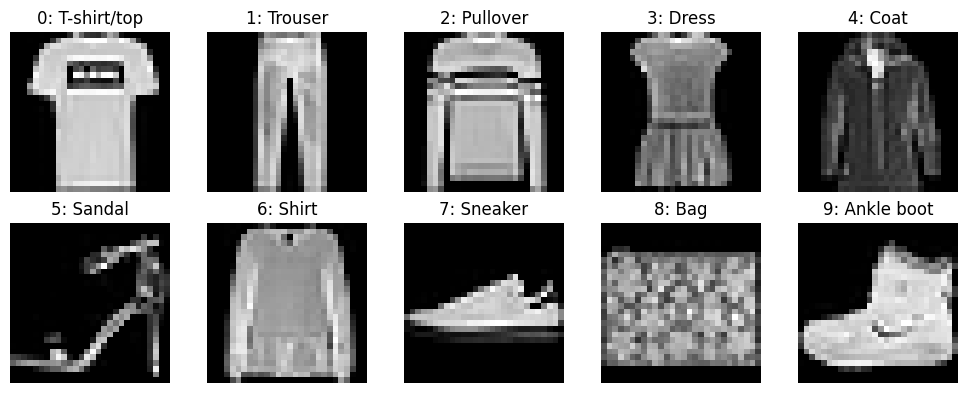

In [8]:
# Contoh gambar dari masing-masing kelas

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
shown = set()

for img, label in raw_train:
    if label not in shown:
        ax = axes[label // 5, label % 5]
        ax.imshow(img.squeeze(), cmap="gray")
        ax.set_title(f"{label}: {classes[label]}")
        ax.axis("off")
        shown.add(label)
    if len(shown) == 10:
        break

plt.tight_layout()
plt.show()

### Eksperimen MLP Classifier

In [9]:
# enc & head dipisah agar lebih mudah ambil z_mlp dan bobotnya
set_seed(seed)
mlp_enc = nn.Sequential(
    nn.Linear(784, 256),
    nn.ReLU(),
    nn.Linear(256, 64),
    nn.ReLU()
).to(device)

mlp_head = nn.Linear(64, 10).to(device)

loss_fn = nn.CrossEntropyLoss()
opt = optim.Adam(list(mlp_enc.parameters()) + list(mlp_head.parameters()), lr=1e-3)

epochs = 15
for epoch in range(epochs):
    mlp_enc.train()
    mlp_head.train()
    total_loss = 0

    for imgs, labels in train_loader:
        x = imgs.view(imgs.size(0), -1).to(device)
        y = labels.to(device)

        opt.zero_grad()
        z = mlp_enc(x)
        out = mlp_head(z)
        loss = loss_fn(out, y)
        loss.backward()
        opt.step()
        total_loss += loss.item()

    mlp_enc.eval()
    mlp_head.eval()
    correct, total = 0, 0


    with torch.no_grad():
        for imgs, labels in val_loader:
            x = imgs.view(imgs.size(0), -1).to(device)
            y = labels.to(device)
            preds = mlp_head(mlp_enc(x)).argmax(dim=1)
            correct += (preds == y).sum().item()
            total += y.size(0)

    val_acc = 100 * correct / total
    print(f"Epoch {epoch+1:02d}/{epochs} | Loss: {total_loss/len(train_loader):.4f} | Val Acc: {val_acc:.2f}%")

Epoch 01/15 | Loss: 0.5976 | Val Acc: 84.47%
Epoch 02/15 | Loss: 0.4064 | Val Acc: 85.13%
Epoch 03/15 | Loss: 0.3592 | Val Acc: 86.33%
Epoch 04/15 | Loss: 0.3325 | Val Acc: 87.04%
Epoch 05/15 | Loss: 0.3129 | Val Acc: 87.50%
Epoch 06/15 | Loss: 0.2959 | Val Acc: 87.31%
Epoch 07/15 | Loss: 0.2837 | Val Acc: 87.74%
Epoch 08/15 | Loss: 0.2701 | Val Acc: 88.19%
Epoch 09/15 | Loss: 0.2627 | Val Acc: 88.24%
Epoch 10/15 | Loss: 0.2532 | Val Acc: 88.21%
Epoch 11/15 | Loss: 0.2422 | Val Acc: 87.90%
Epoch 12/15 | Loss: 0.2368 | Val Acc: 88.51%
Epoch 13/15 | Loss: 0.2266 | Val Acc: 88.56%
Epoch 14/15 | Loss: 0.2210 | Val Acc: 89.07%
Epoch 15/15 | Loss: 0.2157 | Val Acc: 88.07%


In [10]:
mlp_enc.eval()
mlp_head.eval()

correct, total = 0, 0
with torch.no_grad():
    for imgs, labels in test_loader:
        x = imgs.view(imgs.size(0), -1).to(device)
        y = labels.to(device)
        preds = mlp_head(mlp_enc(x)).argmax(dim=1)
        correct += (preds == y).sum().item()
        total += y.size(0)

test_acc = 100 * correct / total
print(f"Test Accuracy MLP: {test_acc:.2f}%")

Test Accuracy MLP: 88.37%


In [11]:
torch.save(mlp_enc.state_dict(), "outputs/models/mlp_enc.pt")
torch.save(mlp_head.state_dict(), "outputs/models/mlp_head.pt")

In [12]:
W1 = mlp_enc[0].weight.detach()
W2 = mlp_enc[2].weight.detach()
W3 = mlp_head.weight.detach()

print("Shape bobot W1:", W1.shape)
print("Shape bobot W2:", W2.shape)
print("Shape bobot W3:", W3.shape)

Shape bobot W1: torch.Size([256, 784])
Shape bobot W2: torch.Size([64, 256])
Shape bobot W3: torch.Size([10, 64])


In [13]:
eye64 = torch.eye(64, device=device)
ortho_err = (W3.T @ W3 - eye64).abs().max().item()
print(f"Max Orthogonality Error: {ortho_err:.4f}")

Max Orthogonality Error: 1.1800


In [14]:
# Non-ortogonalitas baris (W @ W^T != I) & Singular Values
for name, W in [("W1 (256x784)", W1), ("W2 (64x256)", W2), ("W3 (10x64)", W3)]:
    m = W.size(0)
    eye_m = torch.eye(m, device=device)
    row_ortho_err = (W @ W.T - eye_m).abs().max().item()
    svals = torch.linalg.svdvals(W)
    cond_num = (svals.max() / svals.min()).item()
    print(f"{name} | Max ||W W^T - I||: {row_ortho_err:.4f} | "
          f"Singular Values: [{svals.min():.3f}, {svals.max():.3f}] | "
          f"Cond: {cond_num:.2f}")

rank_w3 = torch.linalg.matrix_rank(W3).item()
print(f"Rank efektif W3: {rank_w3}/64 (null space berdimensi {64 - rank_w3} -> non-invertible)")

W1 (256x784) | Max ||W W^T - I||: 30.6842 | Singular Values: [0.360, 12.615] | Cond: 35.03
W2 (64x256) | Max ||W W^T - I||: 5.1669 | Singular Values: [0.378, 6.348] | Cond: 16.78
W3 (10x64) | Max ||W W^T - I||: 2.6265 | Singular Values: [0.801, 2.354] | Cond: 2.94
Rank efektif W3: 10/64 (null space berdimensi 54 -> non-invertible)


###  Top-Down Weight Transposition

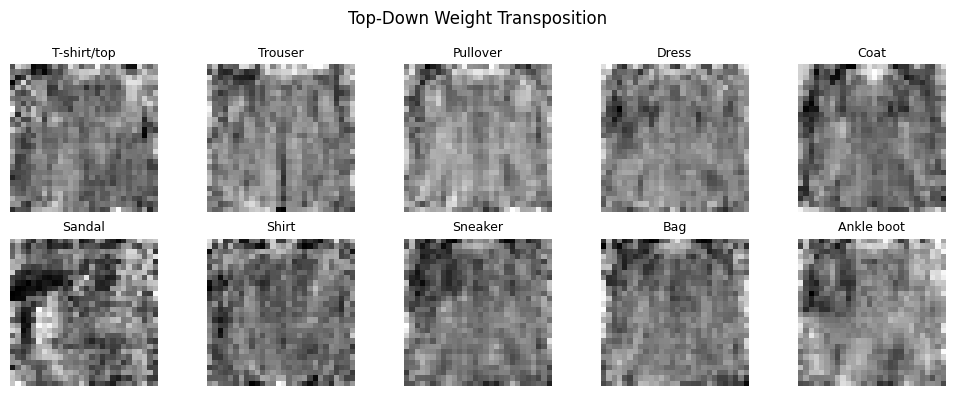

In [15]:
y_onehot = torch.eye(10, device=device)
z_hat = F.relu(y_onehot @ W3)
h1_hat = F.relu(z_hat @ W2)
x_from_y = torch.sigmoid(h1_hat @ W1).view(10, 28, 28).cpu()

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i in range(10):
    ax = axes[i // 5, i % 5]
    ax.imshow(x_from_y[i], cmap="gray")
    ax.set_title(classes[i], fontsize=9)
    ax.axis("off")
plt.suptitle("Top-Down Weight Transposition")
plt.tight_layout()
plt.show()

### Latent Transpose Projection

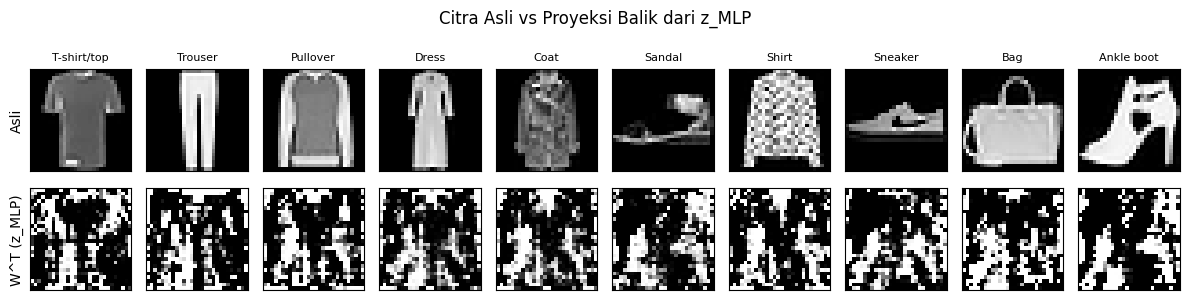

In [16]:
picked_imgs = {}
for img, label in test_data:
    if label not in picked_imgs:
        picked_imgs[label] = img
    if len(picked_imgs) == 10:
        break

sample_imgs = torch.stack([picked_imgs[i] for i in range(10)])
sample_labels = list(range(10))
x_real = sample_imgs.view(10, -1).to(device)

with torch.no_grad():
    z_sample = mlp_enc(x_real)
    x_from_z = torch.sigmoid(F.relu(z_sample @ W2) @ W1).view(10, 28, 28).cpu()

fig, axes = plt.subplots(2, 10, figsize=(12, 3.2))
for i in range(10):
    axes[0, i].imshow(sample_imgs[i].squeeze(), cmap="gray")
    axes[0, i].set_title(classes[sample_labels[i]], fontsize=8)
    axes[0, i].set_xticks([])
    axes[0, i].set_yticks([])

    axes[1, i].imshow(x_from_z[i], cmap="gray")
    axes[1, i].set_xticks([])
    axes[1, i].set_yticks([])

axes[0, 0].set_ylabel("Asli", fontsize=10)
axes[1, 0].set_ylabel("W^T (z_MLP)", fontsize=10)
plt.suptitle("Citra Asli vs Proyeksi Balik dari z_MLP")
plt.tight_layout()
plt.show()

### Frozen Latent Decoding

In [17]:
# Freeze seluruh bobot MLP Classifier
set_seed(seed)
for p in mlp_enc.parameters():
    p.requires_grad = False
for p in mlp_head.parameters():
    p.requires_grad = False
mlp_enc.eval()

# Decoder terpisah (64 -> 256 -> 784)
frozen_dec = nn.Sequential(
    nn.Linear(64, 256),
    nn.ReLU(),
    nn.Linear(256, 784),
    nn.Sigmoid()
).to(device)

mse_fn = nn.MSELoss()
dec_opt = optim.Adam(frozen_dec.parameters(), lr=1e-3)

dec_epochs = 20
for epoch in range(dec_epochs):
    frozen_dec.train()
    total_loss = 0

    for imgs, _ in train_loader:
        x = imgs.view(imgs.size(0), -1).to(device)
        with torch.no_grad():
            z_mlp = mlp_enc(x)

        dec_opt.zero_grad()
        recon = frozen_dec(z_mlp)
        loss = mse_fn(recon, x)
        loss.backward()
        dec_opt.step()
        total_loss += loss.item()

    print(f"Epoch {epoch+1:02d}/{dec_epochs} | Train MSE: {total_loss/len(train_loader):.4f}")

Epoch 01/20 | Train MSE: 0.0372
Epoch 02/20 | Train MSE: 0.0250
Epoch 03/20 | Train MSE: 0.0225
Epoch 04/20 | Train MSE: 0.0214
Epoch 05/20 | Train MSE: 0.0206
Epoch 06/20 | Train MSE: 0.0201
Epoch 07/20 | Train MSE: 0.0196
Epoch 08/20 | Train MSE: 0.0193
Epoch 09/20 | Train MSE: 0.0190
Epoch 10/20 | Train MSE: 0.0187
Epoch 11/20 | Train MSE: 0.0185
Epoch 12/20 | Train MSE: 0.0183
Epoch 13/20 | Train MSE: 0.0181
Epoch 14/20 | Train MSE: 0.0180
Epoch 15/20 | Train MSE: 0.0178
Epoch 16/20 | Train MSE: 0.0177
Epoch 17/20 | Train MSE: 0.0176
Epoch 18/20 | Train MSE: 0.0175
Epoch 19/20 | Train MSE: 0.0174
Epoch 20/20 | Train MSE: 0.0173


In [18]:
psnr_metric = PeakSignalNoiseRatio(data_range=1.0).to(device)
ssim_metric = StructuralSimilarityIndexMeasure(data_range=1.0).to(device)

frozen_dec.eval()
mse_sum = 0.0
total_pixels = 0

with torch.no_grad():
    for imgs, _ in test_loader:
        x_img = imgs.to(device)
        x_flat = x_img.view(x_img.size(0), -1)
        recon_img = frozen_dec(mlp_enc(x_flat)).view(-1, 1, 28, 28)

        mse_sum += F.mse_loss(recon_img, x_img, reduction="sum").item()
        total_pixels += x_img.numel()
        psnr_metric.update(recon_img, x_img)
        ssim_metric.update(recon_img, x_img)

mlp_dec_mse = mse_sum / total_pixels
mlp_dec_psnr = psnr_metric.compute().item()
mlp_dec_ssim = ssim_metric.compute().item()

print(f"Test MSE: {mlp_dec_mse:.5f}")
print(f"PSNR: {mlp_dec_psnr:.2f} dB")
print(f"SSIM: {mlp_dec_ssim:.4f}")

Test MSE: 0.01755
PSNR: 17.56 dB
SSIM: 0.7067


In [19]:
torch.save(frozen_dec.state_dict(), "outputs/models/frozen_dec.pt")

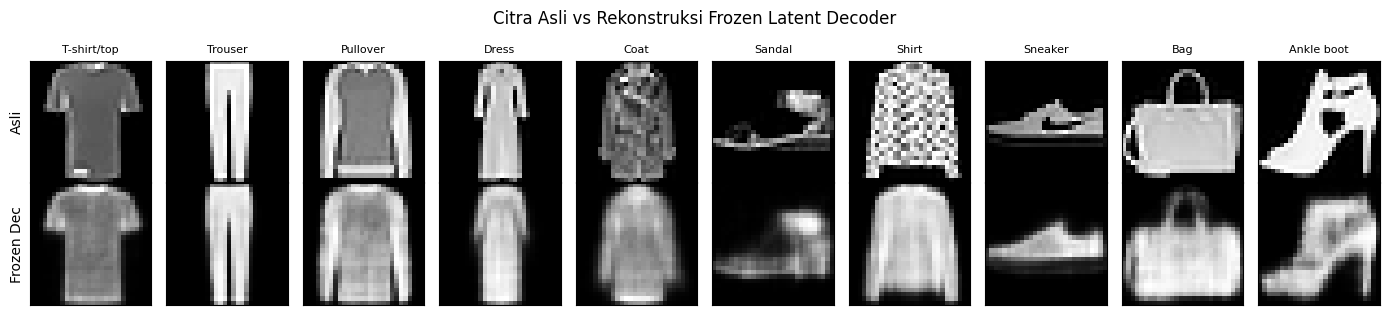

In [20]:
with torch.no_grad():
    x_frozen = frozen_dec(mlp_enc(x_real)).view(10, 28, 28).cpu()

fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for i in range(10):
    axes[0, i].imshow(sample_imgs[i].squeeze(), cmap="gray")
    axes[0, i].set_title(classes[sample_labels[i]], fontsize=8)
    axes[0, i].set_xticks([])
    axes[0, i].set_yticks([])

    axes[1, i].imshow(x_frozen[i], cmap="gray")
    axes[1, i].set_xticks([])
    axes[1, i].set_yticks([])

axes[0, 0].set_ylabel("Asli", fontsize=10)
axes[1, 0].set_ylabel("Frozen Dec", fontsize=10)
plt.suptitle("Citra Asli vs Rekonstruksi Frozen Latent Decoder")
plt.tight_layout()
plt.show()

###  Uji Sampling Generatif pada Ruang Laten MLP Classifier

In [21]:
z_list = []

with torch.no_grad():
    for imgs, _ in test_loader:
        x = imgs.view(imgs.size(0), -1).to(device)
        z_list.append(mlp_enc(x))

all_z_mlp = torch.cat(z_list, dim=0)

mu_z = all_z_mlp.mean(dim=0)
std_z = all_z_mlp.std(dim=0)
zero_pct = (all_z_mlp == 0).float().mean().item() * 100
print(f"Mean range: [{mu_z.min():.2f}, {mu_z.max():.2f}]")
print(f"Std range: [{std_z.min():.2f}, {std_z.max():.2f}]")
print(f"Elemen bernilai 0: {zero_pct:.1f}%")

Mean range: [0.00, 4.89]
Std range: [0.00, 3.97]
Elemen bernilai 0: 49.7%


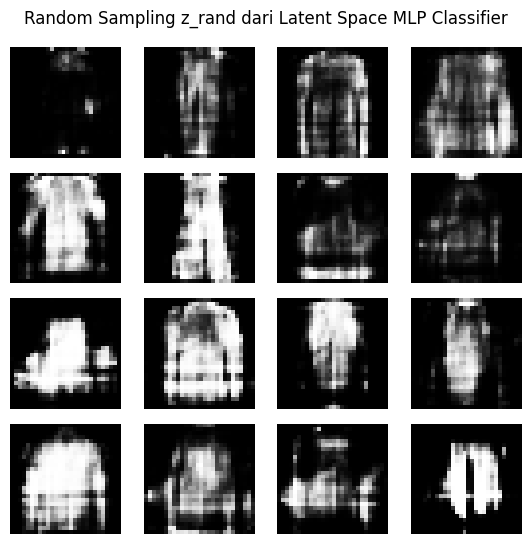

In [22]:
set_seed(seed)
z_rand = mu_z + std_z * torch.randn(16, 64, device=device)

with torch.no_grad():
    x_rand = frozen_dec(z_rand).view(16, 28, 28).cpu()

fig, axes = plt.subplots(4, 4, figsize=(5.5, 5.5))

for i in range(16):
    ax = axes[i // 4, i % 4]
    ax.imshow(x_rand[i], cmap="gray")
    ax.axis("off")
plt.suptitle("Random Sampling z_rand dari Latent Space MLP Classifier")
plt.tight_layout()
plt.show()

## Vanilla Autoencoder

In [23]:
set_seed(seed)

ae_enc = nn.Sequential(
    nn.Linear(784, 256),
    nn.ReLU(),
    nn.Linear(256, 64)
).to(device)

ae_dec = nn.Sequential(
    nn.Linear(64, 256),
    nn.ReLU(),
    nn.Linear(256, 784),
    nn.Sigmoid()
).to(device)

ae_opt = optim.Adam(list(ae_enc.parameters()) + list(ae_dec.parameters()), lr=1e-3)

ae_epochs = 20
ae_losses = []
ae_time = []

for epoch in range(ae_epochs):
    t_start = time.time()
    ae_enc.train()
    ae_dec.train()
    train_loss = 0.0

    for imgs, _ in train_loader:
        x = imgs.view(imgs.size(0), -1).to(device)

        ae_opt.zero_grad()
        recon = ae_dec(ae_enc(x))
        loss = mse_fn(recon, x)
        loss.backward()
        ae_opt.step()
        train_loss += loss.item()

    ep_time = time.time() - t_start

    # Cek validation loss
    ae_enc.eval()
    ae_dec.eval()
    val_loss = 0.0
    with torch.no_grad():
        for imgs, _ in val_loader:
            x = imgs.view(imgs.size(0), -1).to(device)
            val_loss += mse_fn(ae_dec(ae_enc(x)), x).item()

    avg_train = train_loss / len(train_loader)
    avg_val = val_loss / len(val_loader)

    ae_losses.append(avg_train)
    ae_time.append(ep_time)
    print(f"Epoch {epoch+1:02d}/{ae_epochs} | Train MSE: {avg_train:.5f} | Val MSE: {avg_val:.5f} | Time: {ep_time:.2f}s")

Epoch 01/20 | Train MSE: 0.03172 | Val MSE: 0.01859 | Time: 6.64s
Epoch 02/20 | Train MSE: 0.01655 | Val MSE: 0.01499 | Time: 7.62s
Epoch 03/20 | Train MSE: 0.01390 | Val MSE: 0.01306 | Time: 6.90s
Epoch 04/20 | Train MSE: 0.01243 | Val MSE: 0.01189 | Time: 7.28s
Epoch 05/20 | Train MSE: 0.01133 | Val MSE: 0.01102 | Time: 7.53s
Epoch 06/20 | Train MSE: 0.01058 | Val MSE: 0.01033 | Time: 6.71s
Epoch 07/20 | Train MSE: 0.00997 | Val MSE: 0.00997 | Time: 8.02s
Epoch 08/20 | Train MSE: 0.00950 | Val MSE: 0.00953 | Time: 6.82s
Epoch 09/20 | Train MSE: 0.00910 | Val MSE: 0.00910 | Time: 8.04s
Epoch 10/20 | Train MSE: 0.00876 | Val MSE: 0.00876 | Time: 6.96s
Epoch 11/20 | Train MSE: 0.00844 | Val MSE: 0.00849 | Time: 6.91s
Epoch 12/20 | Train MSE: 0.00818 | Val MSE: 0.00825 | Time: 7.51s
Epoch 13/20 | Train MSE: 0.00795 | Val MSE: 0.00810 | Time: 6.70s
Epoch 14/20 | Train MSE: 0.00773 | Val MSE: 0.00783 | Time: 7.73s
Epoch 15/20 | Train MSE: 0.00756 | Val MSE: 0.00774 | Time: 6.68s
Epoch 16/2

In [24]:
torch.save(ae_enc.state_dict(), "outputs/models/ae_enc.pt")
torch.save(ae_dec.state_dict(), "outputs/models/ae_dec.pt")
np.save("outputs/models/ae_losses.npy", np.array(ae_losses))

In [25]:
# Reset metric yang dipakai ulang dari cell MLP
psnr_metric.reset()
ssim_metric.reset()

In [26]:
ae_enc.eval()
ae_dec.eval()
mse_sum = 0.0
total_pixels = 0

with torch.no_grad():

    for imgs, _ in test_loader:
        x_img = imgs.to(device)
        x_flat = x_img.view(x_img.size(0), -1)
        recon_img = ae_dec(ae_enc(x_flat)).view(-1, 1, 28, 28)

        mse_sum += F.mse_loss(recon_img, x_img, reduction="sum").item()
        total_pixels += x_img.numel()
        psnr_metric.update(recon_img, x_img)
        ssim_metric.update(recon_img, x_img)

ae_mse = mse_sum / total_pixels
ae_psnr = psnr_metric.compute().item()
ae_ssim = ssim_metric.compute().item()
ae_avg_time = np.mean(ae_time)

# Inference Latency per batch 64 sampel
x_64 = next(iter(test_loader))[0][:64].view(64, -1).to(device)

with torch.no_grad():

    for _ in range(10):
        _ = ae_dec(ae_enc(x_64))
    if device.type == "cuda":
        torch.cuda.synchronize()

    t0 = time.time()

    for _ in range(100):
        _ = ae_dec(ae_enc(x_64))
    if device.type == "cuda":
        torch.cuda.synchronize()

    ae_latency = ((time.time() - t0) / 100) * 1000  # dalam ms

print("=== Evaluasi Vanilla AE ===")
print(f"Dimensi Laten: 64")
print(f"Training Time/Epoch: {ae_avg_time:.2f} detik")
print(f"Latency Rekonstruksi (enc+dec, batch 64): {ae_latency:.3f} ms")
print(f"Test MSE: {ae_mse:.5f}")
print(f"Test PSNR: {ae_psnr:.2f} dB")
print(f"Test SSIM: {ae_ssim:.4f}")
print("FID Score: N/A (Latent Voids)")

=== Evaluasi Vanilla AE ===
Dimensi Laten: 64
Training Time/Epoch: 7.16 detik
Latency Rekonstruksi (enc+dec, batch 64): 0.166 ms
Test MSE: 0.00698
Test PSNR: 21.56 dB
Test SSIM: 0.8541
FID Score: N/A (Latent Voids)


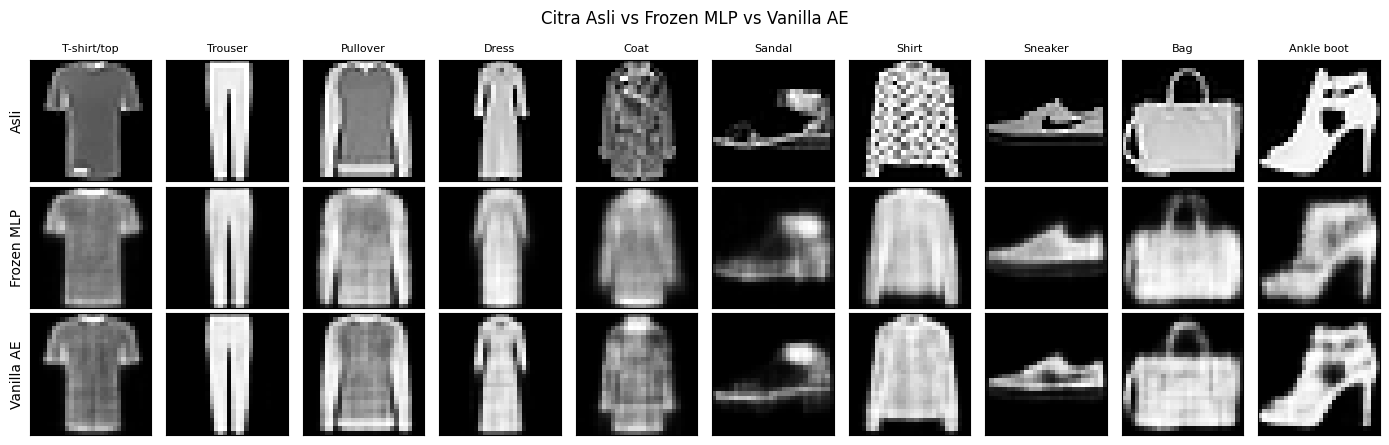

In [27]:
with torch.no_grad():
    x_ae = ae_dec(ae_enc(x_real)).view(10, 28, 28).cpu()

fig, axes = plt.subplots(3, 10, figsize=(14, 4.5))
for i in range(10):
    axes[0, i].imshow(sample_imgs[i].squeeze(), cmap="gray")
    axes[0, i].set_title(classes[sample_labels[i]], fontsize=8)
    axes[0, i].set_xticks([])
    axes[0, i].set_yticks([])

    axes[1, i].imshow(x_frozen[i], cmap="gray")
    axes[1, i].set_xticks([])
    axes[1, i].set_yticks([])

    axes[2, i].imshow(x_ae[i], cmap="gray")
    axes[2, i].set_xticks([])
    axes[2, i].set_yticks([])

axes[0, 0].set_ylabel("Asli", fontsize=10)
axes[1, 0].set_ylabel("Frozen MLP", fontsize=10)
axes[2, 0].set_ylabel("Vanilla AE", fontsize=10)
plt.suptitle("Citra Asli vs Frozen MLP vs Vanilla AE")
plt.tight_layout()
plt.show()

## Sparse Autoencoder

In [28]:
set_seed(seed)

sae_enc = nn.Sequential(
    nn.Linear(784, 256),
    nn.ReLU(),
    nn.Linear(256, 64)
).to(device)

sae_dec = nn.Sequential(
    nn.Linear(64, 256),
    nn.ReLU(),
    nn.Linear(256, 784),
    nn.Sigmoid()
).to(device)

sae_opt = optim.Adam(list(sae_enc.parameters()) + list(sae_dec.parameters()), lr=1e-3)

lam = 1e-4  # bobot penalti sparsity L1
sae_epochs = 20
sae_losses = []
sae_time = []

for epoch in range(sae_epochs):

    t_start = time.time()
    sae_enc.train()
    sae_dec.train()
    train_loss = 0.0

    for imgs, _ in train_loader:
        x = imgs.view(imgs.size(0), -1).to(device)

        sae_opt.zero_grad()
        h = sae_enc(x)
        recon = sae_dec(h)

        recon_loss = mse_fn(recon, x)
        l1_penalty = h.abs().sum(dim=1).mean()
        loss = recon_loss + lam * l1_penalty

        loss.backward()
        sae_opt.step()
        train_loss += loss.item()

    ep_time = time.time() - t_start

    sae_enc.eval()
    sae_dec.eval()
    val_mse = 0.0
    with torch.no_grad():
        for imgs, _ in val_loader:
            x = imgs.view(imgs.size(0), -1).to(device)
            val_mse += mse_fn(sae_dec(sae_enc(x)), x).item()

    avg_train = train_loss / len(train_loader)
    avg_val = val_mse / len(val_loader)

    sae_losses.append(avg_train)
    sae_time.append(ep_time)
    print(f"Epoch {epoch+1:02d}/{sae_epochs} | Train Loss: {avg_train:.5f} | Val MSE: {avg_val:.5f} | Time: {ep_time:.2f}s")

Epoch 01/20 | Train Loss: 0.03416 | Val MSE: 0.01884 | Time: 8.02s
Epoch 02/20 | Train Loss: 0.01854 | Val MSE: 0.01495 | Time: 7.47s
Epoch 03/20 | Train Loss: 0.01562 | Val MSE: 0.01311 | Time: 7.24s
Epoch 04/20 | Train Loss: 0.01390 | Val MSE: 0.01178 | Time: 7.99s
Epoch 05/20 | Train Loss: 0.01271 | Val MSE: 0.01115 | Time: 6.83s
Epoch 06/20 | Train Loss: 0.01187 | Val MSE: 0.01030 | Time: 8.01s
Epoch 07/20 | Train Loss: 0.01123 | Val MSE: 0.00988 | Time: 6.81s
Epoch 08/20 | Train Loss: 0.01071 | Val MSE: 0.00956 | Time: 8.11s
Epoch 09/20 | Train Loss: 0.01027 | Val MSE: 0.00912 | Time: 7.58s
Epoch 10/20 | Train Loss: 0.00989 | Val MSE: 0.00882 | Time: 6.99s
Epoch 11/20 | Train Loss: 0.00957 | Val MSE: 0.00856 | Time: 7.91s
Epoch 12/20 | Train Loss: 0.00927 | Val MSE: 0.00851 | Time: 6.94s
Epoch 13/20 | Train Loss: 0.00901 | Val MSE: 0.00818 | Time: 7.79s
Epoch 14/20 | Train Loss: 0.00878 | Val MSE: 0.00798 | Time: 7.00s
Epoch 15/20 | Train Loss: 0.00861 | Val MSE: 0.00796 | Time: 7

In [29]:
torch.save(sae_enc.state_dict(), "outputs/models/sae_enc.pt")
torch.save(sae_dec.state_dict(), "outputs/models/sae_dec.pt")
np.save("outputs/models/sae_losses.npy", np.array(sae_losses))

In [30]:
# Reset metric
psnr_metric.reset()
ssim_metric.reset()

In [31]:
sae_enc.eval()
sae_dec.eval()
ae_enc.eval()

mse_sum = 0.0
total_pixels = 0
sae_h_list = []
ae_z_list = []

with torch.no_grad():
    for imgs, _ in test_loader:
        x_img = imgs.to(device)
        x_flat = x_img.view(x_img.size(0), -1)

        h = sae_enc(x_flat)
        recon_img = sae_dec(h).view(-1, 1, 28, 28)

        mse_sum += F.mse_loss(recon_img, x_img, reduction="sum").item()
        total_pixels += x_img.numel()
        psnr_metric.update(recon_img, x_img)
        ssim_metric.update(recon_img, x_img)

        sae_h_list.append(h)
        ae_z_list.append(ae_enc(x_flat))

sae_mse = mse_sum / total_pixels
sae_psnr = psnr_metric.compute().item()
sae_ssim = ssim_metric.compute().item()
sae_avg_time = np.mean(sae_time)

# Sparsity Sparse AE vs Vanilla AE
all_h = torch.cat(sae_h_list, dim=0)
all_z = torch.cat(ae_z_list, dim=0)

sae_zero = (all_h == 0).float().mean().item() * 100
sae_near_zero = (all_h.abs() < 0.05).float().mean().item() * 100
ae_near_zero = (all_z.abs() < 0.05).float().mean().item() * 100
sae_l1 = all_h.abs().sum(dim=1).mean().item()
ae_l1 = all_z.abs().sum(dim=1).mean().item()

# Inference latency per batch 64
with torch.no_grad():

    for _ in range(10):
        _ = sae_dec(sae_enc(x_64))
    if device.type == "cuda":
        torch.cuda.synchronize()

    t0 = time.time()

    for _ in range(100):
        _ = sae_dec(sae_enc(x_64))
    if device.type == "cuda":
        torch.cuda.synchronize()
    sae_latency = ((time.time() - t0) / 100) * 1000

print("=== Evaluasi Sparse AE ===")
print("Dimensi Laten: 64")
print(f"Lambda L1: {lam}")
print(f"Training Time/Epoch: {sae_avg_time:.2f} detik")
print(f"Latency Rekonstruksi (enc+dec, batch 64): {sae_latency:.3f} ms")
print(f"Test MSE: {sae_mse:.5f}")
print(f"Test PSNR: {sae_psnr:.2f} dB")
print(f"Test SSIM: {sae_ssim:.4f}")
print("FID Score: N/A (Latent Voids)")

=== Evaluasi Sparse AE ===
Dimensi Laten: 64
Lambda L1: 0.0001
Training Time/Epoch: 7.45 detik
Latency Rekonstruksi (enc+dec, batch 64): 0.187 ms
Test MSE: 0.00731
Test PSNR: 21.36 dB
Test SSIM: 0.8487
FID Score: N/A (Latent Voids)


In [34]:
# ReLU + L1 untuk memisahkan efek murni penalti L1 vs efek non-negatif dari ReLU
set_seed(seed)

sae_relu_enc = nn.Sequential(
    nn.Linear(784, 256),
    nn.ReLU(),
    nn.Linear(256, 64),
    nn.ReLU()
).to(device)

sae_relu_dec = nn.Sequential(
    nn.Linear(64, 256),
    nn.ReLU(),
    nn.Linear(256, 784),
    nn.Sigmoid()
).to(device)

sae_relu_opt = optim.Adam(list(sae_relu_enc.parameters()) + list(sae_relu_dec.parameters()), lr=1e-3)

for epoch in range(sae_epochs):
    sae_relu_enc.train()
    sae_relu_dec.train()
    train_loss = 0.0
    for imgs, _ in train_loader:
        x = imgs.view(imgs.size(0), -1).to(device)
        sae_relu_opt.zero_grad()
        h = sae_relu_enc(x)
        loss = mse_fn(sae_relu_dec(h), x) + lam * h.abs().sum(dim=1).mean()
        loss.backward()
        sae_relu_opt.step()
        train_loss += loss.item()
    print(f"[ReLU+L1] Epoch {epoch+1:02d}/{sae_epochs} | Train Loss: {train_loss/len(train_loader):.5f}")

psnr_metric.reset()
ssim_metric.reset()
sae_relu_enc.eval()
sae_relu_dec.eval()

mse_sum = 0.0
total_pixels = 0
h_relu_list = []

with torch.no_grad():
    for imgs, _ in test_loader:
        x_img = imgs.to(device)
        x_flat = x_img.view(x_img.size(0), -1)

        h = sae_relu_enc(x_flat)
        recon_img = sae_relu_dec(h).view(-1, 1, 28, 28)
        mse_sum += F.mse_loss(recon_img, x_img, reduction="sum").item()
        total_pixels += x_img.numel()

        psnr_metric.update(recon_img, x_img)
        ssim_metric.update(recon_img, x_img)
        h_relu_list.append(h)

sae_relu_mse = mse_sum / total_pixels
sae_relu_psnr = psnr_metric.compute().item()
sae_relu_ssim = ssim_metric.compute().item()
all_h_relu = torch.cat(h_relu_list, dim=0)
sae_relu_zero = (all_h_relu == 0).float().mean().item() * 100
sae_relu_near_zero = (all_h_relu.abs() < 0.05).float().mean().item() * 100
sae_relu_l1 = all_h_relu.abs().sum(dim=1).mean().item()

print("=== Evaluasi Sparse AE (ReLU + L1) ===")
print(f"Test MSE: {sae_relu_mse:.5f}")
print(f"Test PSNR: {sae_relu_psnr:.2f} dB")
print(f"Test SSIM: {sae_relu_ssim:.4f}")
print(f"Aktivasi tepat 0: {sae_relu_zero:.1f}%")
print(f"Aktivasi hampir 0 (<0.05): {sae_relu_near_zero:.1f}%")
print(f"Rata-rata ||h||_1: {sae_relu_l1:.2f}")

[ReLU+L1] Epoch 01/20 | Train Loss: 0.03757
[ReLU+L1] Epoch 02/20 | Train Loss: 0.01986
[ReLU+L1] Epoch 03/20 | Train Loss: 0.01724
[ReLU+L1] Epoch 04/20 | Train Loss: 0.01582
[ReLU+L1] Epoch 05/20 | Train Loss: 0.01486
[ReLU+L1] Epoch 06/20 | Train Loss: 0.01418
[ReLU+L1] Epoch 07/20 | Train Loss: 0.01362
[ReLU+L1] Epoch 08/20 | Train Loss: 0.01318
[ReLU+L1] Epoch 09/20 | Train Loss: 0.01279
[ReLU+L1] Epoch 10/20 | Train Loss: 0.01248
[ReLU+L1] Epoch 11/20 | Train Loss: 0.01220
[ReLU+L1] Epoch 12/20 | Train Loss: 0.01196
[ReLU+L1] Epoch 13/20 | Train Loss: 0.01174
[ReLU+L1] Epoch 14/20 | Train Loss: 0.01155
[ReLU+L1] Epoch 15/20 | Train Loss: 0.01135
[ReLU+L1] Epoch 16/20 | Train Loss: 0.01119
[ReLU+L1] Epoch 17/20 | Train Loss: 0.01103
[ReLU+L1] Epoch 18/20 | Train Loss: 0.01090
[ReLU+L1] Epoch 19/20 | Train Loss: 0.01076
[ReLU+L1] Epoch 20/20 | Train Loss: 0.01065
=== Evaluasi Sparse AE (ReLU + L1) ===
Test MSE: 0.00974
Test PSNR: 20.11 dB
Test SSIM: 0.8049
Aktivasi tepat 0: 52.1%
A

In [35]:
print(f"Sparse AE aktivasi tepat 0: {sae_zero:.1f}%")
print(f"Sparse AE hampir 0 (<0.05): {sae_near_zero:.1f}%")
print(f"Vanilla AE hampir 0 (<0.05): {ae_near_zero:.1f}%")
print(f"Rata-rata ||h||_1 Sparse AE: {sae_l1:.2f}")
print(f"Rata-rata ||z||_1 Vanilla AE: {ae_l1:.2f}")

Sparse AE aktivasi tepat 0: 0.0%
Sparse AE hampir 0 (<0.05): 32.6%
Vanilla AE hampir 0 (<0.05): 2.7%
Rata-rata ||h||_1 Sparse AE: 7.66
Rata-rata ||z||_1 Vanilla AE: 80.95


In [36]:
# Mini-Sweep Lambda L1 (Linear Latent 64)
# melengkapi lambda=0 (Vanilla AE) & lambda=1e-4 (Sparse AE)

sweep_results = [
    (0.0, ae_mse, ae_psnr, ae_ssim, ae_near_zero, ae_l1),
    (1e-4, sae_mse, sae_psnr, sae_ssim, sae_near_zero, sae_l1),
]

for lam_val in [1e-5, 1e-3]:
    set_seed(seed)
    enc_sw = nn.Sequential(nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, 64)).to(device)
    dec_sw = nn.Sequential(nn.Linear(64, 256), nn.ReLU(), nn.Linear(256, 784), nn.Sigmoid()).to(device)
    opt_sw = optim.Adam(list(enc_sw.parameters()) + list(dec_sw.parameters()), lr=1e-3)

    for epoch in range(sae_epochs):
        enc_sw.train()
        dec_sw.train()
        for imgs, _ in train_loader:
            x = imgs.view(imgs.size(0), -1).to(device)
            opt_sw.zero_grad()
            h = enc_sw(x)
            loss = mse_fn(dec_sw(h), x) + lam_val * h.abs().sum(dim=1).mean()
            loss.backward()
            opt_sw.step()

    psnr_metric.reset()
    ssim_metric.reset()
    enc_sw.eval()
    dec_sw.eval()
    mse_s, n_pix, h_list = 0.0, 0, []
    with torch.no_grad():
        for imgs, _ in test_loader:
            x_img = imgs.to(device)
            h = enc_sw(x_img.view(x_img.size(0), -1))
            recon_img = dec_sw(h).view(-1, 1, 28, 28)
            mse_s += F.mse_loss(recon_img, x_img, reduction="sum").item()
            n_pix += x_img.numel()
            psnr_metric.update(recon_img, x_img)
            ssim_metric.update(recon_img, x_img)
            h_list.append(h)

    all_h_sw = torch.cat(h_list, dim=0)
    sw_mse = mse_s / n_pix
    sw_psnr = psnr_metric.compute().item()
    sw_ssim = ssim_metric.compute().item()
    sw_nz = (all_h_sw.abs() < 0.05).float().mean().item() * 100
    sw_l1 = all_h_sw.abs().sum(dim=1).mean().item()
    sweep_results.append((lam_val, sw_mse, sw_psnr, sw_ssim, sw_nz, sw_l1))

sweep_results.sort(key=lambda r: r[0])
print("=== Mini-Sweep Lambda L1 (Linear Latent 64, 20 Epoch) ===")
for lv, m, p, s, nz, l1 in sweep_results:
    print(f"lambda={lv:<7g} | MSE: {m:.5f} | PSNR: {p:.2f} dB | SSIM: {s:.4f} | <0.05: {nz:5.1f}% | ||h||_1: {l1:6.2f}")

=== Mini-Sweep Lambda L1 (Linear Latent 64, 20 Epoch) ===
lambda=0       | MSE: 0.00698 | PSNR: 21.56 dB | SSIM: 0.8541 | <0.05:   2.7% | ||h||_1:  80.95
lambda=1e-05   | MSE: 0.00681 | PSNR: 21.67 dB | SSIM: 0.8557 | <0.05:   8.0% | ||h||_1:  29.82
lambda=0.0001  | MSE: 0.00731 | PSNR: 21.36 dB | SSIM: 0.8487 | <0.05:  32.6% | ||h||_1:   7.66
lambda=0.001   | MSE: 0.01110 | PSNR: 19.55 dB | SSIM: 0.7730 | <0.05:  91.9% | ||h||_1:   1.19


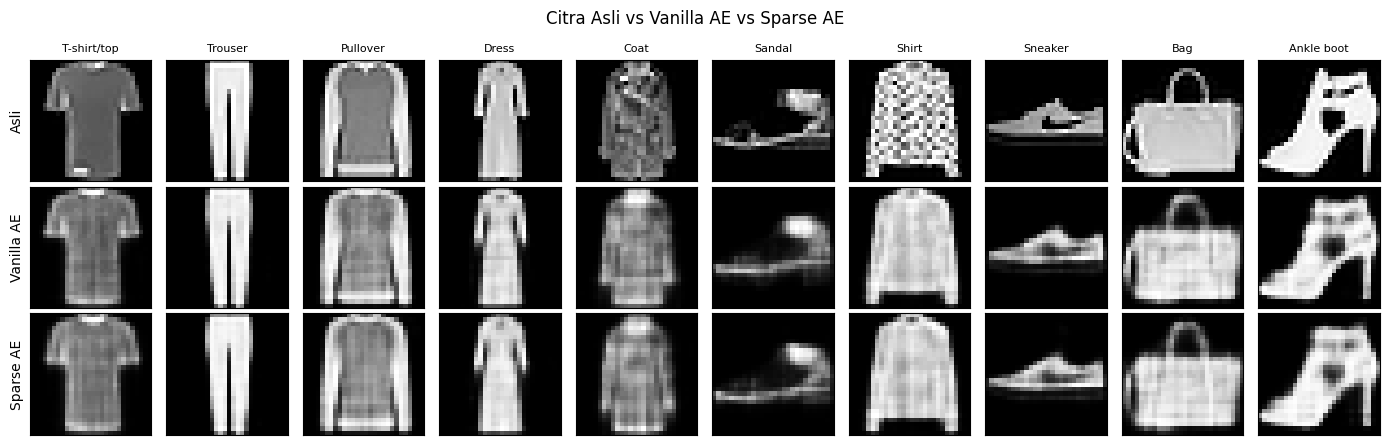

In [37]:
with torch.no_grad():
    x_sae = sae_dec(sae_enc(x_real)).view(10, 28, 28).cpu()

fig, axes = plt.subplots(3, 10, figsize=(14, 4.5))
for i in range(10):
    axes[0, i].imshow(sample_imgs[i].squeeze(), cmap="gray")
    axes[0, i].set_title(classes[sample_labels[i]], fontsize=8)
    axes[0, i].set_xticks([])
    axes[0, i].set_yticks([])

    axes[1, i].imshow(x_ae[i], cmap="gray")
    axes[1, i].set_xticks([])
    axes[1, i].set_yticks([])

    axes[2, i].imshow(x_sae[i], cmap="gray")
    axes[2, i].set_xticks([])
    axes[2, i].set_yticks([])

axes[0, 0].set_ylabel("Asli", fontsize=10)
axes[1, 0].set_ylabel("Vanilla AE", fontsize=10)
axes[2, 0].set_ylabel("Sparse AE", fontsize=10)
plt.suptitle("Citra Asli vs Vanilla AE vs Sparse AE")
plt.tight_layout()
plt.show()

## Variational Autoencoder (VAE)

In [38]:
set_seed(seed)

vae_enc = nn.Sequential(
    nn.Linear(784, 256),
    nn.ReLU()
).to(device)

vae_mu = nn.Linear(256, 64).to(device)
vae_logvar = nn.Linear(256, 64).to(device)

vae_dec = nn.Sequential(
    nn.Linear(64, 256),
    nn.ReLU(),
    nn.Linear(256, 784),
    nn.Sigmoid()
).to(device)

vae_params = (
    list(vae_enc.parameters()) +
    list(vae_mu.parameters()) +
    list(vae_logvar.parameters()) +
    list(vae_dec.parameters())
)
vae_opt = optim.Adam(vae_params, lr=1e-3)

vae_epochs = 20
vae_losses = []
vae_time = []

for epoch in range(vae_epochs):
    t_start = time.time()
    vae_enc.train()
    vae_mu.train()
    vae_logvar.train()
    vae_dec.train()

    train_loss = 0.0

    for imgs, _ in train_loader:
        x = imgs.view(imgs.size(0), -1).to(device)

        vae_opt.zero_grad()
        h = vae_enc(x)
        mu = vae_mu(h)
        logvar = vae_logvar(h)

        std = torch.exp(0.5 * logvar)
        z = mu + std * torch.randn_like(std)
        recon = vae_dec(z)


        bce = F.binary_cross_entropy(recon, x, reduction="sum") / x.size(0)
        kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / x.size(0)
        loss = bce + kl

        loss.backward()
        vae_opt.step()
        train_loss += loss.item()

    ep_time = time.time() - t_start

    vae_enc.eval()
    vae_mu.eval()
    vae_logvar.eval()
    vae_dec.eval()

    val_loss = 0.0
    with torch.no_grad():
        for imgs, _ in val_loader:
            x = imgs.view(imgs.size(0), -1).to(device)
            h = vae_enc(x)
            mu = vae_mu(h)
            logvar = vae_logvar(h)
            z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)
            recon = vae_dec(z)

            bce = F.binary_cross_entropy(recon, x, reduction="sum") / x.size(0)
            kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / x.size(0)
            val_loss += (bce + kl).item()

    avg_train = train_loss / len(train_loader)
    avg_val = val_loss / len(val_loader)

    vae_losses.append(avg_train)
    vae_time.append(ep_time)
    print(f"Epoch {epoch+1:02d}/{vae_epochs} | Train Loss: {avg_train:.2f} | Val Loss: {avg_val:.2f} | Time: {ep_time:.2f}s")

Epoch 01/20 | Train Loss: 300.81 | Val Loss: 275.38 | Time: 8.23s
Epoch 02/20 | Train Loss: 268.83 | Val Loss: 264.46 | Time: 8.00s
Epoch 03/20 | Train Loss: 259.24 | Val Loss: 256.78 | Time: 6.93s
Epoch 04/20 | Train Loss: 253.66 | Val Loss: 252.54 | Time: 8.14s
Epoch 05/20 | Train Loss: 250.57 | Val Loss: 250.02 | Time: 7.10s
Epoch 06/20 | Train Loss: 248.50 | Val Loss: 248.47 | Time: 7.87s
Epoch 07/20 | Train Loss: 247.24 | Val Loss: 247.36 | Time: 8.25s
Epoch 08/20 | Train Loss: 246.30 | Val Loss: 246.59 | Time: 7.97s
Epoch 09/20 | Train Loss: 245.55 | Val Loss: 245.88 | Time: 8.77s
Epoch 10/20 | Train Loss: 244.94 | Val Loss: 245.55 | Time: 8.26s
Epoch 11/20 | Train Loss: 244.50 | Val Loss: 245.22 | Time: 7.49s
Epoch 12/20 | Train Loss: 244.09 | Val Loss: 244.54 | Time: 8.51s
Epoch 13/20 | Train Loss: 243.75 | Val Loss: 244.53 | Time: 7.46s
Epoch 14/20 | Train Loss: 243.48 | Val Loss: 244.16 | Time: 7.76s
Epoch 15/20 | Train Loss: 243.17 | Val Loss: 243.75 | Time: 8.31s
Epoch 16/2

In [39]:
torch.save(vae_enc.state_dict(), "outputs/models/vae_enc.pt")
torch.save(vae_mu.state_dict(), "outputs/models/vae_mu.pt")
torch.save(vae_logvar.state_dict(), "outputs/models/vae_logvar.pt")
torch.save(vae_dec.state_dict(), "outputs/models/vae_dec.pt")
np.save("outputs/models/vae_losses.npy", np.array(vae_losses))

In [40]:
# Reset metric
psnr_metric.reset()
ssim_metric.reset()

In [41]:
# Fitur gambar asli cukup dihitung sekali
fid_metric = FrechetInceptionDistance(feature=2048, reset_real_features=False).to(device)

vae_enc.eval()
vae_mu.eval()
vae_logvar.eval()
vae_dec.eval()

mse_sum = 0.0
total_pixels = 0

with torch.no_grad():
    for imgs, _ in test_loader:
        x_img = imgs.to(device)
        x_flat = x_img.view(x_img.size(0), -1)

        mu = vae_mu(vae_enc(x_flat))
        recon_img = vae_dec(mu).view(-1, 1, 28, 28)

        mse_sum += F.mse_loss(recon_img, x_img, reduction="sum").item()
        total_pixels += x_img.numel()
        psnr_metric.update(recon_img, x_img)
        ssim_metric.update(recon_img, x_img)

        real_rgb = (x_img.clamp(0, 1) * 255).to(torch.uint8).repeat(1, 3, 1, 1)
        fid_metric.update(real_rgb, real=True)

vae_mse = mse_sum / total_pixels
vae_psnr = psnr_metric.compute().item()
vae_ssim = ssim_metric.compute().item()
vae_avg_time = np.mean(vae_time)

# Generate sample baru untuk hitung FID Score
set_seed(seed)
n_total = len(test_data)
n_done = 0
with torch.no_grad():
    while n_done < n_total:
        bs = min(128, n_total - n_done)
        z_rand = torch.randn(bs, 64, device=device)
        fake_img = vae_dec(z_rand).view(-1, 1, 28, 28)
        fake_rgb = (fake_img.clamp(0, 1) * 255).to(torch.uint8).repeat(1, 3, 1, 1)
        fid_metric.update(fake_rgb, real=False)
        n_done += bs

vae_fid = fid_metric.compute().item()

# Inference Latency single-pass decoder
z_64 = torch.randn(64, 64, device=device)

with torch.no_grad():
    for _ in range(10):
        _ = vae_dec(z_64)
    if device.type == "cuda":
        torch.cuda.synchronize()

    t0 = time.time()

    for _ in range(100):
        _ = vae_dec(z_64)
    if device.type == "cuda":
        torch.cuda.synchronize()
    vae_latency = ((time.time() - t0) / 100) * 1000

print("=== Evaluasi VAE ===")
print("Dimensi Laten: 64")
print(f"Training Time/Epoch: {vae_avg_time:.2f} detik")
print(f"Latency Generation (prior->citra, batch 64): {vae_latency:.3f} ms")
print(f"Test MSE: {vae_mse:.5f}")
print(f"Test PSNR: {vae_psnr:.2f} dB")
print(f"Test SSIM: {vae_ssim:.4f}")
print(f"FID Score: {vae_fid:.2f}")

=== Evaluasi VAE ===
Dimensi Laten: 64
Training Time/Epoch: 7.91 detik
Latency Generation (prior->citra, batch 64): 0.143 ms
Test MSE: 0.01341
Test PSNR: 18.72 dB
Test SSIM: 0.7616
FID Score: 91.92


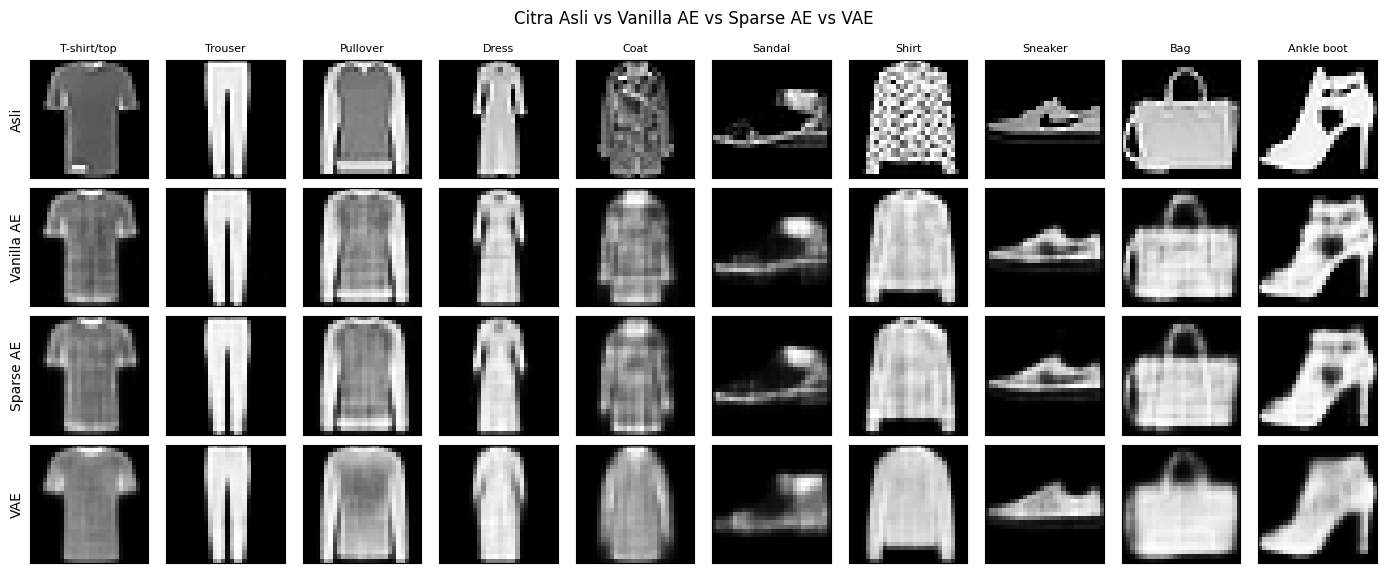

In [42]:
with torch.no_grad():
    x_vae = vae_dec(vae_mu(vae_enc(x_real))).view(10, 28, 28).cpu()

fig, axes = plt.subplots(4, 10, figsize=(14, 5.8))
rows = [sample_imgs.squeeze(), x_ae, x_sae, x_vae]
row_names = ["Asli", "Vanilla AE", "Sparse AE", "VAE"]

for r in range(4):
    for c in range(10):
        axes[r, c].imshow(rows[r][c], cmap="gray")
        if r == 0:
            axes[r, c].set_title(classes[sample_labels[c]], fontsize=8)
        axes[r, c].set_xticks([])
        axes[r, c].set_yticks([])
    axes[r, 0].set_ylabel(row_names[r], fontsize=10)

plt.suptitle("Citra Asli vs Vanilla AE vs Sparse AE vs VAE")
plt.tight_layout()
plt.show()

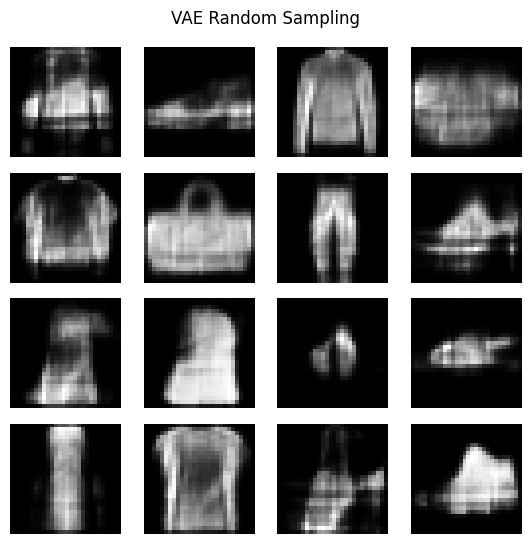

In [43]:
set_seed(seed)
with torch.no_grad():
    z_16 = torch.randn(16, 64, device=device)
    vae_samples = vae_dec(z_16).view(16, 28, 28).cpu()

fig, axes = plt.subplots(4, 4, figsize=(5.5, 5.5))
for i in range(16):
    ax = axes[i // 4, i % 4]
    ax.imshow(vae_samples[i], cmap="gray")
    ax.axis("off")

plt.suptitle("VAE Random Sampling")
plt.tight_layout()
plt.show()

## Generative Adversarial Network (GAN)

In [44]:
set_seed(seed)

z_dim = 100

# Generator
gan_G = nn.Sequential(
    nn.Linear(z_dim, 256),
    nn.LeakyReLU(0.2),
    nn.Linear(256, 512),
    nn.LeakyReLU(0.2),
    nn.Linear(512, 784),
    nn.Tanh()
).to(device)

# Discriminator
gan_D = nn.Sequential(
    nn.Linear(784, 512),
    nn.LeakyReLU(0.2),
    nn.Dropout(0.3),
    nn.Linear(512, 256),
    nn.LeakyReLU(0.2),
    nn.Dropout(0.3),
    nn.Linear(256, 1),
    nn.Sigmoid()
).to(device)

bce_fn = nn.BCELoss()
opt_G = optim.Adam(gan_G.parameters(), lr=2e-4, betas=(0.5, 0.999))
opt_D = optim.Adam(gan_D.parameters(), lr=2e-4, betas=(0.5, 0.999))

gan_epochs = 30
gan_g_losses = []
gan_d_losses = []
gan_time = []

for epoch in range(gan_epochs):
    t_start = time.time()
    gan_G.train()
    gan_D.train()
    d_total = 0.0
    g_total = 0.0

    for imgs, _ in train_loader:
        bs = imgs.size(0)

        real_x = imgs.view(bs, -1).to(device) * 2 - 1
        real_y = torch.ones(bs, 1, device=device)
        fake_y = torch.zeros(bs, 1, device=device)

        # Train Discriminator
        opt_D.zero_grad()
        z = torch.randn(bs, z_dim, device=device)
        fake_x = gan_G(z).detach()

        d_loss_real = bce_fn(gan_D(real_x), real_y)
        d_loss_fake = bce_fn(gan_D(fake_x), fake_y)
        d_loss = d_loss_real + d_loss_fake
        d_loss.backward()
        opt_D.step()

        # Train Generator
        opt_G.zero_grad()
        z = torch.randn(bs, z_dim, device=device)
        gen_x = gan_G(z)
        g_loss = bce_fn(gan_D(gen_x), real_y)
        g_loss.backward()
        opt_G.step()

        d_total += d_loss.item()
        g_total += g_loss.item()

    ep_time = time.time() - t_start
    avg_d = d_total / len(train_loader)
    avg_g = g_total / len(train_loader)

    gan_d_losses.append(avg_d)
    gan_g_losses.append(avg_g)
    gan_time.append(ep_time)
    print(f"Epoch {epoch+1:02d}/{gan_epochs} | D Loss: {avg_d:.4f} | G Loss: {avg_g:.4f} | Time: {ep_time:.2f}s")

Epoch 01/30 | D Loss: 0.6491 | G Loss: 1.7976 | Time: 9.12s
Epoch 02/30 | D Loss: 0.5886 | G Loss: 2.6130 | Time: 9.87s
Epoch 03/30 | D Loss: 0.7677 | G Loss: 2.0988 | Time: 8.91s
Epoch 04/30 | D Loss: 0.8091 | G Loss: 1.8931 | Time: 9.29s
Epoch 05/30 | D Loss: 0.8021 | G Loss: 1.9532 | Time: 9.94s
Epoch 06/30 | D Loss: 0.8510 | G Loss: 1.8080 | Time: 9.20s
Epoch 07/30 | D Loss: 0.8920 | G Loss: 1.7217 | Time: 9.15s
Epoch 08/30 | D Loss: 0.9187 | G Loss: 1.6394 | Time: 10.03s
Epoch 09/30 | D Loss: 0.9352 | G Loss: 1.5842 | Time: 9.31s
Epoch 10/30 | D Loss: 0.9428 | G Loss: 1.5695 | Time: 9.17s
Epoch 11/30 | D Loss: 0.9659 | G Loss: 1.5184 | Time: 9.88s
Epoch 12/30 | D Loss: 0.9905 | G Loss: 1.4587 | Time: 9.63s
Epoch 13/30 | D Loss: 1.0037 | G Loss: 1.4048 | Time: 9.59s
Epoch 14/30 | D Loss: 1.0423 | G Loss: 1.3312 | Time: 9.92s
Epoch 15/30 | D Loss: 1.0480 | G Loss: 1.3034 | Time: 9.52s
Epoch 16/30 | D Loss: 1.0670 | G Loss: 1.2624 | Time: 9.44s
Epoch 17/30 | D Loss: 1.0745 | G Loss: 

In [45]:
torch.save(gan_G.state_dict(), "outputs/models/gan_G.pt")
torch.save(gan_D.state_dict(), "outputs/models/gan_D.pt")

np.save("outputs/models/gan_g_losses.npy", np.array(gan_g_losses))
np.save("outputs/models/gan_d_losses.npy", np.array(gan_d_losses))

In [46]:
# Reset metric
fid_metric.reset()

In [47]:
gan_G.eval()

Sequential(
  (0): Linear(in_features=100, out_features=256, bias=True)
  (1): LeakyReLU(negative_slope=0.2)
  (2): Linear(in_features=256, out_features=512, bias=True)
  (3): LeakyReLU(negative_slope=0.2)
  (4): Linear(in_features=512, out_features=784, bias=True)
  (5): Tanh()
)

In [48]:
# Generate sampel baru untuk hitung FID Score
set_seed(seed)
n_total = len(test_data)
n_done = 0

with torch.no_grad():
    while n_done < n_total:
        bs = min(128, n_total - n_done)
        z_rand = torch.randn(bs, z_dim, device=device)


        fake_img = (gan_G(z_rand).view(-1, 1, 28, 28) + 1) / 2
        fake_rgb = (fake_img.clamp(0, 1) * 255).to(torch.uint8).repeat(1, 3, 1, 1)
        fid_metric.update(fake_rgb, real=False)
        n_done += bs

gan_fid = fid_metric.compute().item()
gan_avg_time = np.mean(gan_time)

# inference latency single-pass
z_gan_64 = torch.randn(64, z_dim, device=device)
with torch.no_grad():
    for _ in range(10):
        _ = gan_G(z_gan_64)
    if device.type == "cuda":
        torch.cuda.synchronize()

    t0 = time.time()
    for _ in range(100):
        _ = gan_G(z_gan_64)
    if device.type == "cuda":
        torch.cuda.synchronize()
    gan_latency = ((time.time() - t0) / 100) * 1000

print(" === Evaluasi Vanilla GAN ===")
print("Dimensi Laten: 100 (Prior Noise)")
print(f"Training Time/Epoch: {gan_avg_time:.2f} detik")
print(f"Latency Generation (prior->citra, batch 64): {gan_latency:.3f} ms")
print("Test MSE: N/A (Tanpa Encoder)")
print("Test PSNR: N/A")
print("Test SSIM: N/A")
print(f"FID Score: {gan_fid:.2f}")

 === Evaluasi Vanilla GAN ===
Dimensi Laten: 100 (Prior Noise)
Training Time/Epoch: 9.42 detik
Latency Generation (prior->citra, batch 64): 0.133 ms
Test MSE: N/A (Tanpa Encoder)
Test PSNR: N/A
Test SSIM: N/A
FID Score: 131.84


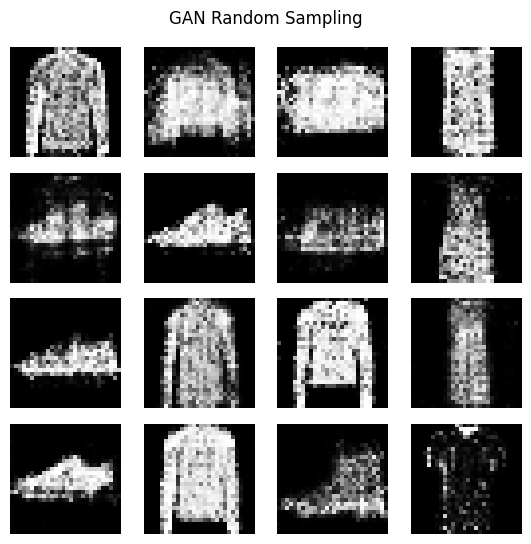

In [49]:
set_seed(seed)
with torch.no_grad():
    z_16 = torch.randn(16, z_dim, device=device)
    gan_samples = ((gan_G(z_16).view(16, 28, 28) + 1) / 2).clamp(0, 1).cpu()

fig, axes = plt.subplots(4, 4, figsize=(5.5, 5.5))
for i in range(16):
    ax = axes[i // 4, i % 4]
    ax.imshow(gan_samples[i], cmap="gray")
    ax.axis("off")

plt.suptitle("GAN Random Sampling")
plt.tight_layout()
plt.show()

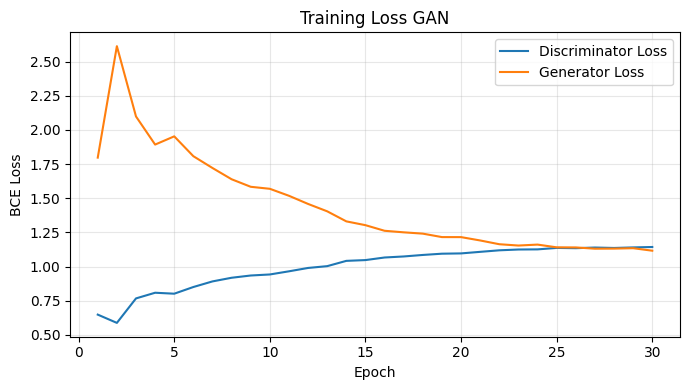

In [50]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, gan_epochs + 1), gan_d_losses, label="Discriminator Loss")
plt.plot(range(1, gan_epochs + 1), gan_g_losses, label="Generator Loss")
plt.xlabel("Epoch")
plt.ylabel("BCE Loss")
plt.title("Training Loss GAN")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Deep Convolutional GAN (DCGAN)

In [51]:
set_seed(seed)

def init_weights(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02)
        nn.init.zeros_(m.bias)

In [52]:
# Generator (ConvTranspose)
dcgan_G = nn.Sequential(
    nn.Unflatten(1, (z_dim, 1, 1)),
    nn.ConvTranspose2d(z_dim, 256, kernel_size=7, stride=1, padding=0, bias=False),
    nn.BatchNorm2d(256),
    nn.ReLU(True),
    nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1, bias=False),
    nn.BatchNorm2d(128),
    nn.ReLU(True),
    nn.ConvTranspose2d(128, 1, kernel_size=4, stride=2, padding=1, bias=False),
    nn.Tanh()
).to(device)

# Discriminator (Conv)
dcgan_D = nn.Sequential(
    nn.Conv2d(1, 64, kernel_size=4, stride=2, padding=1, bias=False),
    nn.LeakyReLU(0.2, inplace=True),
    nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1, bias=False),
    nn.BatchNorm2d(128),
    nn.LeakyReLU(0.2, inplace=True),
    nn.Conv2d(128, 1, kernel_size=7, stride=1, padding=0, bias=False),
    nn.Flatten(),
    nn.Sigmoid()
).to(device)

dcgan_G.apply(init_weights)
dcgan_D.apply(init_weights)

opt_dcgan_G = optim.Adam(dcgan_G.parameters(), lr=2e-4, betas=(0.5, 0.999))
opt_dcgan_D = optim.Adam(dcgan_D.parameters(), lr=2e-4, betas=(0.5, 0.999))

dcgan_epochs = 30
dcgan_g_losses = []
dcgan_d_losses = []
dcgan_time = []

for epoch in range(dcgan_epochs):
    t_start = time.time()
    dcgan_G.train()
    dcgan_D.train()
    d_total = 0.0
    g_total = 0.0

    for imgs, _ in train_loader:
        bs = imgs.size(0)
        real_x = imgs.to(device) * 2 - 1
        real_y = torch.ones(bs, 1, device=device)
        fake_y = torch.zeros(bs, 1, device=device)

        # Train Discriminator
        opt_dcgan_D.zero_grad()
        z = torch.randn(bs, z_dim, device=device)
        fake_x = dcgan_G(z).detach()

        d_loss_real = bce_fn(dcgan_D(real_x), real_y)
        d_loss_fake = bce_fn(dcgan_D(fake_x), fake_y)
        d_loss = d_loss_real + d_loss_fake
        d_loss.backward()
        opt_dcgan_D.step()

        # Train Generator
        opt_dcgan_G.zero_grad()
        z = torch.randn(bs, z_dim, device=device)
        gen_x = dcgan_G(z)
        g_loss = bce_fn(dcgan_D(gen_x), real_y)
        g_loss.backward()
        opt_dcgan_G.step()

        d_total += d_loss.item()
        g_total += g_loss.item()

    ep_time = time.time() - t_start
    avg_d = d_total / len(train_loader)
    avg_g = g_total / len(train_loader)

    dcgan_d_losses.append(avg_d)
    dcgan_g_losses.append(avg_g)
    dcgan_time.append(ep_time)
    print(f"Epoch {epoch+1:02d}/{dcgan_epochs} | D Loss: {avg_d:.4f} | G Loss: {avg_g:.4f} | Time: {ep_time:.2f}s")

Epoch 01/30 | D Loss: 0.6611 | G Loss: 1.7190 | Time: 23.10s
Epoch 02/30 | D Loss: 0.5898 | G Loss: 1.7871 | Time: 23.21s
Epoch 03/30 | D Loss: 0.8370 | G Loss: 1.4097 | Time: 23.52s
Epoch 04/30 | D Loss: 0.9287 | G Loss: 1.2913 | Time: 23.62s
Epoch 05/30 | D Loss: 0.9513 | G Loss: 1.2591 | Time: 23.64s
Epoch 06/30 | D Loss: 0.9776 | G Loss: 1.2468 | Time: 23.84s
Epoch 07/30 | D Loss: 1.0152 | G Loss: 1.2070 | Time: 23.93s
Epoch 08/30 | D Loss: 1.0422 | G Loss: 1.1717 | Time: 23.90s
Epoch 09/30 | D Loss: 1.0797 | G Loss: 1.1564 | Time: 23.96s
Epoch 10/30 | D Loss: 1.1070 | G Loss: 1.1285 | Time: 24.14s
Epoch 11/30 | D Loss: 1.0985 | G Loss: 1.1057 | Time: 24.27s
Epoch 12/30 | D Loss: 1.1151 | G Loss: 1.0988 | Time: 24.41s
Epoch 13/30 | D Loss: 1.1284 | G Loss: 1.0919 | Time: 24.33s
Epoch 14/30 | D Loss: 1.1300 | G Loss: 1.0755 | Time: 24.45s
Epoch 15/30 | D Loss: 1.1466 | G Loss: 1.0698 | Time: 24.28s
Epoch 16/30 | D Loss: 1.1584 | G Loss: 1.0583 | Time: 24.60s
Epoch 17/30 | D Loss: 1.

In [53]:
torch.save(dcgan_G.state_dict(), "outputs/models/dcgan_G.pt")
torch.save(dcgan_D.state_dict(), "outputs/models/dcgan_D.pt")

np.save("outputs/models/dcgan_g_losses.npy", np.array(dcgan_g_losses))
np.save("outputs/models/dcgan_d_losses.npy", np.array(dcgan_d_losses))

In [54]:
# Reset metric
fid_metric.reset()

In [55]:
dcgan_G.eval()

Sequential(
  (0): Unflatten(dim=1, unflattened_size=(100, 1, 1))
  (1): ConvTranspose2d(100, 256, kernel_size=(7, 7), stride=(1, 1), bias=False)
  (2): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (3): ReLU(inplace=True)
  (4): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
  (5): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (6): ReLU(inplace=True)
  (7): ConvTranspose2d(128, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
  (8): Tanh()
)

In [56]:
# Generate sampel baru untuk hitung FID Score
set_seed(seed)
n_total = len(test_data)
n_done = 0

with torch.no_grad():
    while n_done < n_total:
        bs = min(128, n_total - n_done)
        z_rand = torch.randn(bs, z_dim, device=device)
        fake_img = (dcgan_G(z_rand) + 1) / 2
        fake_rgb = (fake_img.clamp(0, 1) * 255).to(torch.uint8).repeat(1, 3, 1, 1)
        fid_metric.update(fake_rgb, real=False)
        n_done += bs

dcgan_fid = fid_metric.compute().item()
dcgan_avg_time = np.mean(dcgan_time)

# inference Latency single-pass
z_dcgan_64 = torch.randn(64, z_dim, device=device)
with torch.no_grad():
    for _ in range(10):
        _ = dcgan_G(z_dcgan_64)
    if device.type == "cuda":
        torch.cuda.synchronize()

    t0 = time.time()
    for _ in range(100):
        _ = dcgan_G(z_dcgan_64)
    if device.type == "cuda":
        torch.cuda.synchronize()
    dcgan_latency = ((time.time() - t0) / 100) * 1000


print("=== Evaluasi DCGAN ===")
print("Dimensi Laten: 100 (Prior Noise)")
print(f"Training Time/Epoch: {dcgan_avg_time:.2f} detik")
print(f"Latency Generation (prior->citra, batch 64): {dcgan_latency:.3f} ms")
print("Test MSE: N/A (Tanpa Encoder)")
print("Test PSNR: N/A")
print("Test SSIM: N/A")
print(f"FID Score: {dcgan_fid:.2f}")

=== Evaluasi DCGAN ===
Dimensi Laten: 100 (Prior Noise)
Training Time/Epoch: 24.22 detik
Latency Generation (prior->citra, batch 64): 4.030 ms
Test MSE: N/A (Tanpa Encoder)
Test PSNR: N/A
Test SSIM: N/A
FID Score: 20.32


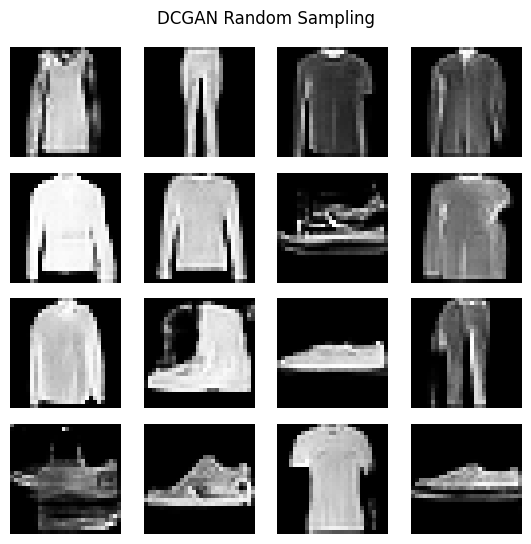

In [57]:
set_seed(seed)

with torch.no_grad():
    z_16 = torch.randn(16, z_dim, device=device)
    dcgan_samples = ((dcgan_G(z_16) + 1) / 2).clamp(0, 1).squeeze(1).cpu()

fig, axes = plt.subplots(4, 4, figsize=(5.5, 5.5))

for i in range(16):
    ax = axes[i // 4, i % 4]
    ax.imshow(dcgan_samples[i], cmap="gray")
    ax.axis("off")

plt.suptitle("DCGAN Random Sampling")
plt.tight_layout()
plt.show()

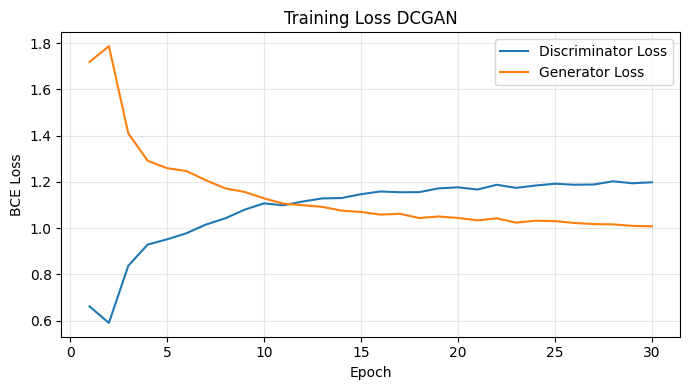

In [58]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, dcgan_epochs + 1), dcgan_d_losses, label="Discriminator Loss")
plt.plot(range(1, dcgan_epochs + 1), dcgan_g_losses, label="Generator Loss")
plt.xlabel("Epoch")
plt.ylabel("BCE Loss")
plt.title("Training Loss DCGAN")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Denoising Diffusion Probabilistic Models (DDPM)

In [59]:
set_seed(seed)

T = 300
betas = torch.linspace(1e-4, 0.035, T, device=device)
alpha = 1.0 - betas
alpha_bar = torch.cumprod(alpha, dim=0)

In [60]:
def get_time_embeded(t, dim=64):
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
    args = t[:, None].float() * freqs[None, :]
    return torch.cat([torch.sin(args), torch.cos(args)], dim=-1)

In [61]:
def conv_block(in_c, out_c):
    return nn.Sequential(
        nn.Conv2d(in_c, out_c, 3, padding=1),
        nn.GroupNorm(8, out_c),
        nn.SiLU(),
        nn.Conv2d(out_c, out_c, 3, padding=1),
        nn.GroupNorm(8, out_c),
        nn.SiLU()
    )

In [62]:
class MiniUNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.time_mlp = nn.Sequential(
            nn.Linear(64, 128),
            nn.SiLU(),
            nn.Linear(128, 128)
        )
        self.down1 = conv_block(1, 64)
        self.pool1 = nn.Conv2d(64, 64, 4, stride=2, padding=1)
        self.down2 = conv_block(64, 128)
        self.pool2 = nn.Conv2d(128, 128, 4, stride=2, padding=1)
        self.mid = conv_block(128, 128)

        self.up2 = nn.ConvTranspose2d(128, 128, 4, stride=2, padding=1)
        self.dec2 = conv_block(256, 64)
        self.up1 = nn.ConvTranspose2d(64, 64, 4, stride=2, padding=1)
        self.dec1 = conv_block(128, 64)
        self.out = nn.Conv2d(64, 1, 1)

        self.t_d1 = nn.Linear(128, 64)
        self.t_d2 = nn.Linear(128, 128)
        self.t_mid = nn.Linear(128, 128)
        self.t_u2 = nn.Linear(128, 64)
        self.t_u1 = nn.Linear(128, 64)

    def forward(self, x, t):
        te = self.time_mlp(get_time_embeded(t, 64))

        h1 = self.down1(x) + self.t_d1(te)[:, :, None, None]
        h2 = self.down2(self.pool1(h1)) + self.t_d2(te)[:, :, None, None]
        m = self.mid(self.pool2(h2)) + self.t_mid(te)[:, :, None, None]

        u2 = torch.cat([self.up2(m), h2], dim=1)
        u2 = self.dec2(u2) + self.t_u2(te)[:, :, None, None]
        u1 = torch.cat([self.up1(u2), h1], dim=1)
        u1 = self.dec1(u1) + self.t_u1(te)[:, :, None, None]
        return self.out(u1)

ddpm_net = MiniUNet().to(device)
ddpm_opt = optim.Adam(ddpm_net.parameters(), lr=2e-4)

In [63]:
ddpm_epochs = 30
ddpm_losses = []
ddpm_time = []

for epoch in range(ddpm_epochs):
    t_start = time.time()
    ddpm_net.train()
    train_loss = 0.0

    for imgs, _ in train_loader:
        x0 = imgs.to(device) * 2 - 1
        bs = x0.size(0)
        t = torch.randint(0, T, (bs,), device=device)
        noise = torch.randn_like(x0)

        # Forward
        ab = alpha_bar[t][:, None, None, None]
        x_t = torch.sqrt(ab) * x0 + torch.sqrt(1 - ab) * noise

        ddpm_opt.zero_grad()
        pred_noise = ddpm_net(x_t, t)
        loss = mse_fn(pred_noise, noise)
        loss.backward()
        ddpm_opt.step()
        train_loss += loss.item()

    ep_time = time.time() - t_start

    ddpm_net.eval()
    val_loss = 0.0

    with torch.no_grad():

        for imgs, _ in val_loader:
            x0 = imgs.to(device) * 2 - 1
            bs = x0.size(0)
            t = torch.randint(0, T, (bs,), device=device)
            noise = torch.randn_like(x0)
            ab = alpha_bar[t][:, None, None, None]
            x_t = torch.sqrt(ab) * x0 + torch.sqrt(1 - ab) * noise
            val_loss += mse_fn(ddpm_net(x_t, t), noise).item()

    avg_train = train_loss / len(train_loader)
    avg_val = val_loss / len(val_loader)

    ddpm_losses.append(avg_train)
    ddpm_time.append(ep_time)
    print(f"Epoch {epoch+1:02d}/{ddpm_epochs} | Train MSE: {avg_train:.5f} | Val MSE: {avg_val:.5f} | Time: {ep_time:.2f}s")

Epoch 01/30 | Train MSE: 0.11224 | Val MSE: 0.07793 | Time: 35.50s
Epoch 02/30 | Train MSE: 0.07440 | Val MSE: 0.07250 | Time: 35.33s
Epoch 03/30 | Train MSE: 0.06776 | Val MSE: 0.06547 | Time: 35.44s
Epoch 04/30 | Train MSE: 0.06443 | Val MSE: 0.06411 | Time: 35.39s
Epoch 05/30 | Train MSE: 0.06313 | Val MSE: 0.06330 | Time: 35.19s
Epoch 06/30 | Train MSE: 0.06155 | Val MSE: 0.06049 | Time: 35.18s
Epoch 07/30 | Train MSE: 0.05968 | Val MSE: 0.05922 | Time: 34.95s
Epoch 08/30 | Train MSE: 0.05933 | Val MSE: 0.05886 | Time: 34.94s
Epoch 09/30 | Train MSE: 0.05888 | Val MSE: 0.05959 | Time: 34.86s
Epoch 10/30 | Train MSE: 0.05802 | Val MSE: 0.05698 | Time: 34.85s
Epoch 11/30 | Train MSE: 0.05795 | Val MSE: 0.05904 | Time: 34.86s
Epoch 12/30 | Train MSE: 0.05754 | Val MSE: 0.05631 | Time: 34.79s
Epoch 13/30 | Train MSE: 0.05646 | Val MSE: 0.05507 | Time: 34.91s
Epoch 14/30 | Train MSE: 0.05678 | Val MSE: 0.05668 | Time: 34.73s
Epoch 15/30 | Train MSE: 0.05592 | Val MSE: 0.05453 | Time: 34

In [64]:
torch.save(ddpm_net.state_dict(), "outputs/models/ddpm_net.pt")
np.save("outputs/models/ddpm_losses.npy", np.array(ddpm_losses))

In [65]:
# Reverse
def sample_ddpm(n):
    ddpm_net.eval()

    with torch.no_grad():
        x = torch.randn(n, 1, 28, 28, device=device)

        for i in reversed(range(T)):
            t = torch.full((n,), i, device=device, dtype=torch.long)
            pred = ddpm_net(x, t)
            a = alpha[i]
            ab = alpha_bar[i]
            b = betas[i]

            x = (1 / torch.sqrt(a)) * (x - ((1 - a) / torch.sqrt(1 - ab)) * pred)
            if i > 0:
                var = b * (1 - alpha_bar[i - 1]) / (1 - ab)
                x = x + torch.sqrt(var) * torch.randn_like(x)

        return (x.clamp(-1, 1) + 1) / 2

In [66]:
fid_metric.reset()

In [67]:
# Generate sample baru untuk hitung FID Score
set_seed(seed)
n_total = len(test_data)
n_done = 0

while n_done < n_total:
    bs = min(256, n_total - n_done)
    fake_img = sample_ddpm(bs)
    fake_rgb = (fake_img.clamp(0, 1) * 255).to(torch.uint8).repeat(1, 3, 1, 1)
    fid_metric.update(fake_rgb, real=False)
    n_done += bs

ddpm_fid = fid_metric.compute().item()
ddpm_avg_time = np.mean(ddpm_time)

# inference latency
_ = sample_ddpm(64)

if device.type == "cuda":
    torch.cuda.synchronize()

t0 = time.time()

for _ in range(5):
    _ = sample_ddpm(64)

if device.type == "cuda":
    torch.cuda.synchronize()

ddpm_latency = ((time.time() - t0) / 5) * 1000

print("=== Evaluasi DDPM ===")
print("Dimensi Laten: 28x28 (Dimensi Citra)")
print(f"Timesteps (T): {T}")
print(f"Training Time/Epoch: {ddpm_avg_time:.2f} detik")
print(f"Latency Generation (prior->citra, batch 64): {ddpm_latency:.2f} ms")
print("Test MSE: N/A (Denoising Model)")
print("Test PSNR: N/A")
print("Test SSIM: N/A")
print(f"FID Score: {ddpm_fid:.2f}")

=== Evaluasi DDPM ===
Dimensi Laten: 28x28 (Dimensi Citra)
Timesteps (T): 300
Training Time/Epoch: 34.93 detik
Latency Generation (prior->citra, batch 64): 3590.29 ms
Test MSE: N/A (Denoising Model)
Test PSNR: N/A
Test SSIM: N/A
FID Score: 19.97


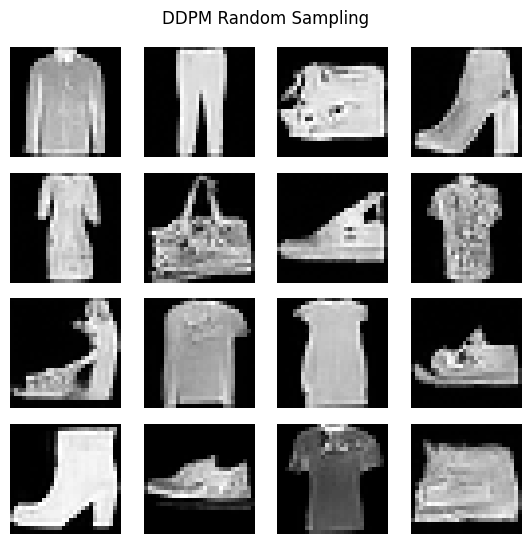

In [68]:
set_seed(seed)
ddpm_samples = sample_ddpm(16).squeeze(1).cpu()

fig, axes = plt.subplots(4, 4, figsize=(5.5, 5.5))

for i in range(16):
    ax = axes[i // 4, i % 4]
    ax.imshow(ddpm_samples[i], cmap="gray")
    ax.axis("off")

plt.suptitle(f"DDPM Random Sampling")
plt.tight_layout()
plt.show()

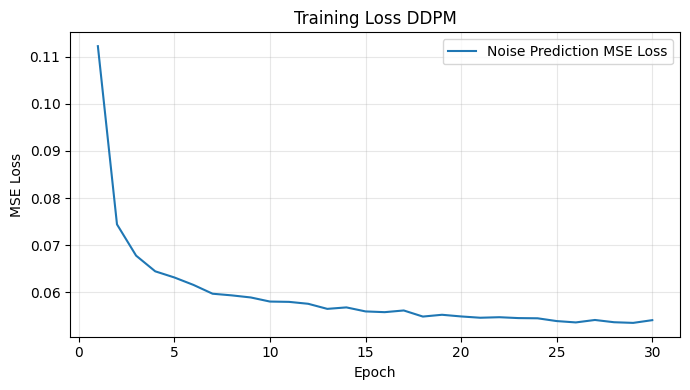

In [69]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, ddpm_epochs + 1), ddpm_losses, label="Noise Prediction MSE Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training Loss DDPM")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Hasil Eksperimen

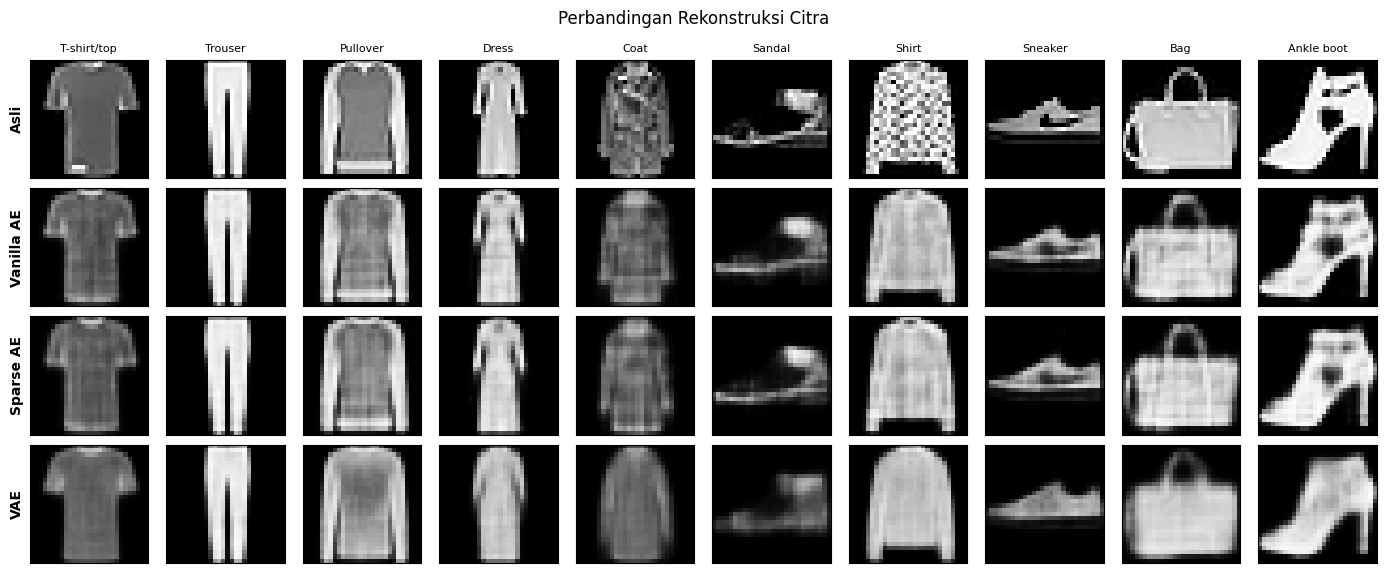

In [70]:
# Perbandingan Autoencoder

fig, axes = plt.subplots(4, 10, figsize=(14, 5.8))
rows = [sample_imgs.squeeze(1), x_ae, x_sae, x_vae]
row_names = ["Asli", "Vanilla AE", "Sparse AE", "VAE"]

for r in range(4):
    for c in range(10):
        axes[r, c].imshow(rows[r][c], cmap="gray", vmin=0, vmax=1)
        if r == 0:
            axes[r, c].set_title(classes[sample_labels[c]], fontsize=8)
        axes[r, c].set_xticks([])
        axes[r, c].set_yticks([])
    axes[r, 0].set_ylabel(row_names[r], fontsize=10, fontweight="bold")

plt.suptitle("Perbandingan Rekonstruksi Citra", fontsize=12)
plt.tight_layout()
plt.savefig("outputs/figs/rekonstruksi_ae.png", dpi=300, bbox_inches="tight")
plt.show()

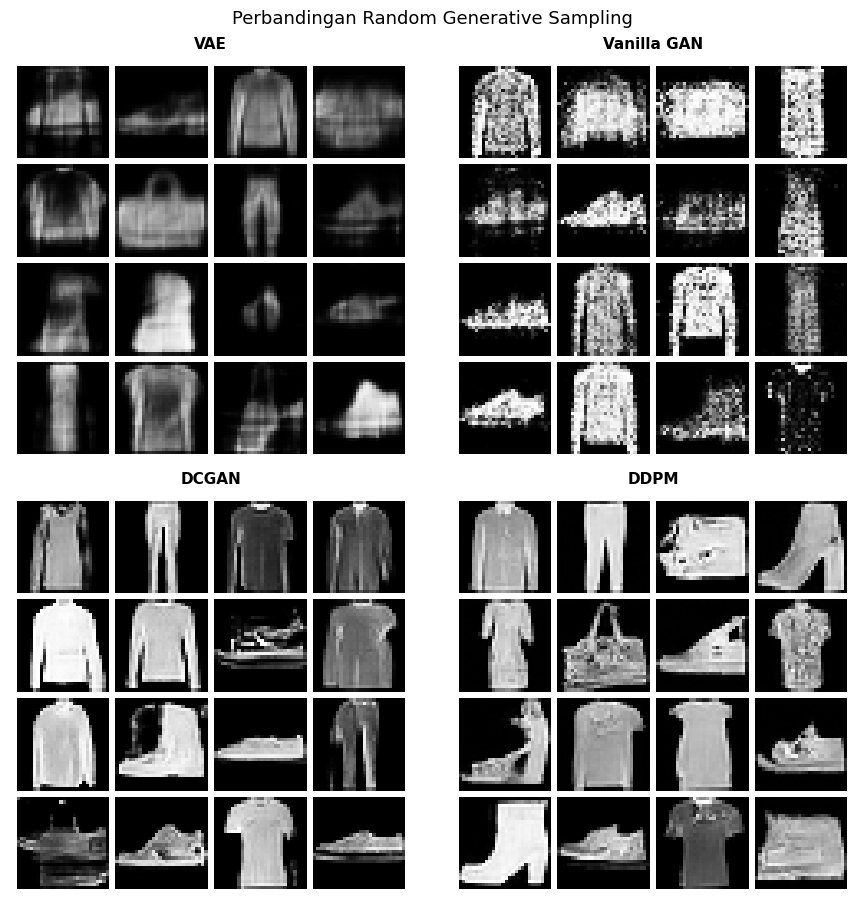

In [71]:
# Perbandingan Random Generative Sampling

panels = [
    ("VAE", vae_samples),
    ("Vanilla GAN", gan_samples),
    ("DCGAN", dcgan_samples),
    (f"DDPM", ddpm_samples),
]

fig, axes = plt.subplots(2, 2, figsize=(9, 9.2))

for idx, (title, imgs) in enumerate(panels):
    ax = axes[idx // 2, idx % 2]
    grid = make_grid(imgs.detach().cpu().view(16, 1, 28, 28), nrow=4, padding=2, pad_value=1.0)
    ax.imshow(grid[0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(title, fontsize=11, fontweight="bold", pad=8)
    ax.axis("off")

plt.suptitle("Perbandingan Random Generative Sampling", fontsize=13)
plt.tight_layout()
plt.savefig("outputs/figs/random_sampling.png", dpi=300, bbox_inches="tight")
plt.show()

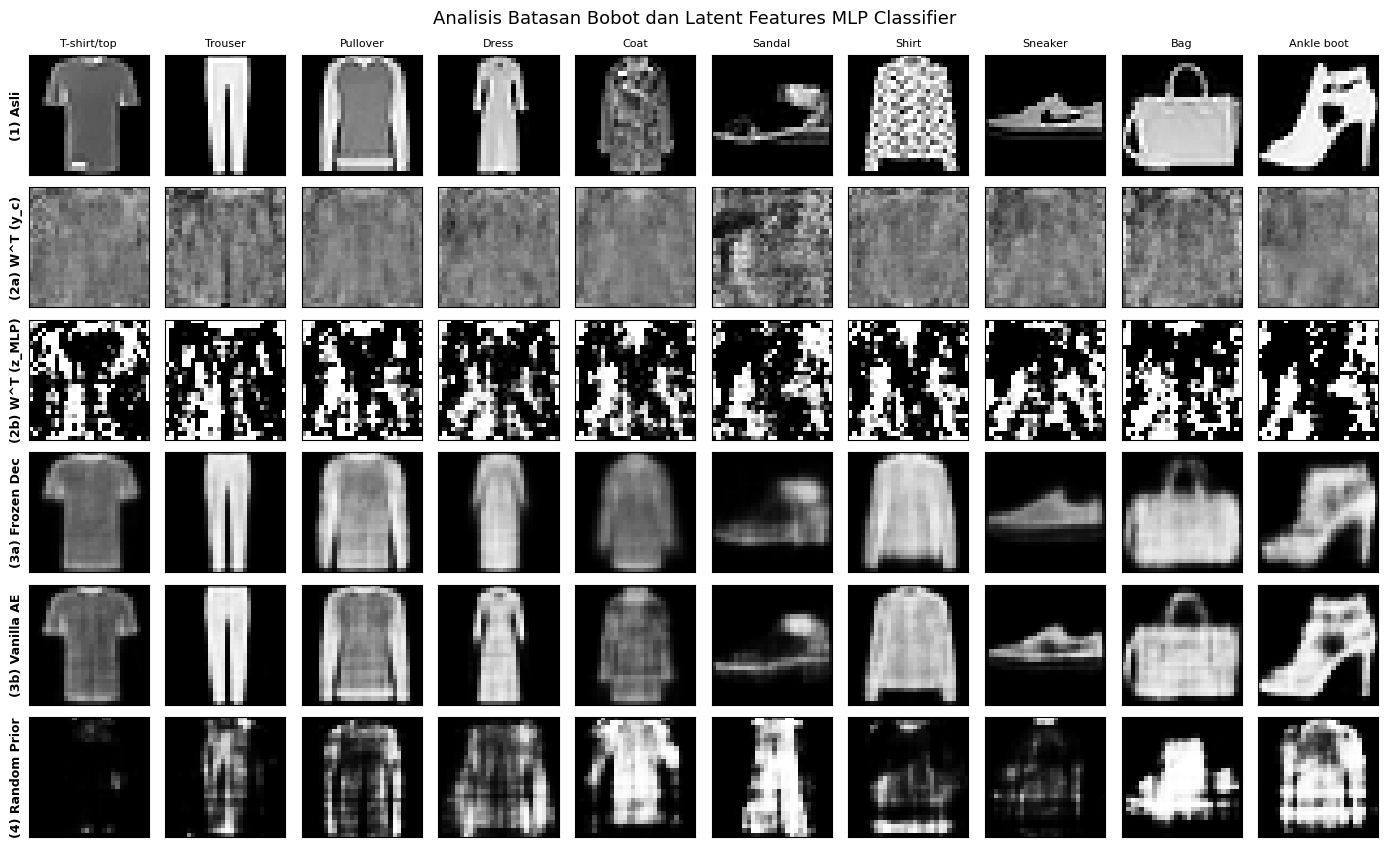

In [72]:
# Batasan Bobot dan Latent Features MLP Classifier

mlp_enc.eval()
mlp_head.eval()
frozen_dec.eval()

w_enc = [m.weight for m in mlp_enc.modules() if isinstance(m, nn.Linear)]
w_head = [m.weight for m in mlp_head.modules() if isinstance(m, nn.Linear)]
w1, w2, w3 = w_enc[0], w_enc[1], w_head[0]

z_all = []

with torch.no_grad():
    for imgs, _ in test_loader:
        z_all.append(mlp_enc(imgs.view(imgs.size(0), -1).to(device)))

z_all = torch.cat(z_all, dim=0)
mu_z = z_all.mean(dim=0)
std_z = z_all.std(dim=0)

with torch.no_grad():
    z_mlp = mlp_enc(x_real)

    # Proyeksi balik W^T dari vektor kelas y_c
    y_idx = torch.as_tensor(sample_labels, device=device, dtype=torch.long)
    y_c = F.one_hot(y_idx, num_classes=len(classes)).float()
    x_wt_yc = torch.sigmoid(F.relu(F.relu(y_c @ w3) @ w2) @ w1).view(10, 28, 28).cpu()

    # Proyeksi balik W^T dari fitur laten z_MLP
    x_wt_z = torch.sigmoid(F.relu(z_mlp @ w2) @ w1).view(10, 28, 28).cpu()

    # Rekonstruksi Frozen Latent Decoder dari z_MLP
    x_frozen = frozen_dec(z_mlp).view(10, 28, 28).cpu()

    # Random Prior Sampling z_rand
    set_seed(seed)
    z_rand_mlp = mu_z + std_z * torch.randn(10, mu_z.numel(), device=device)
    x_mlp_rand = frozen_dec(z_rand_mlp).view(10, 28, 28).cpu()

fig, axes = plt.subplots(6, 10, figsize=(14, 8.6))

mlp_rows = [
    sample_imgs.squeeze(1),
    x_wt_yc,
    x_wt_z,
    x_frozen,
    x_ae,
    x_mlp_rand,
]

mlp_names = [
    "(1) Asli",
    "(2a) W^T (y_c)",
    "(2b) W^T (z_MLP)",
    "(3a) Frozen Dec",
    "(3b) Vanilla AE",
    "(4) Random Prior",
]

for r in range(6):
    for c in range(10):
        axes[r, c].imshow(mlp_rows[r][c], cmap="gray", vmin=0, vmax=1)
        if r == 0:
            axes[r, c].set_title(classes[sample_labels[c]], fontsize=8)
        axes[r, c].set_xticks([])
        axes[r, c].set_yticks([])
    axes[r, 0].set_ylabel(mlp_names[r], fontsize=9, fontweight="bold")

plt.suptitle("Analisis Batasan Bobot dan Latent Features MLP Classifier", fontsize=13)
plt.tight_layout()
plt.savefig("outputs/figs/mlp_analisis.png", dpi=300, bbox_inches="tight")
plt.show()

Kelas A: Trouser
Kelas B: Ankle boot
Confidence Vanilla GAN >> Trouser: 100.0%
Confidence Vanilla GAN >> Ankle boot: 100.0%
Confidence DCGAN >> Trouser: 100.0%
Confidence DCGAN >> Ankle boot: 100.0%


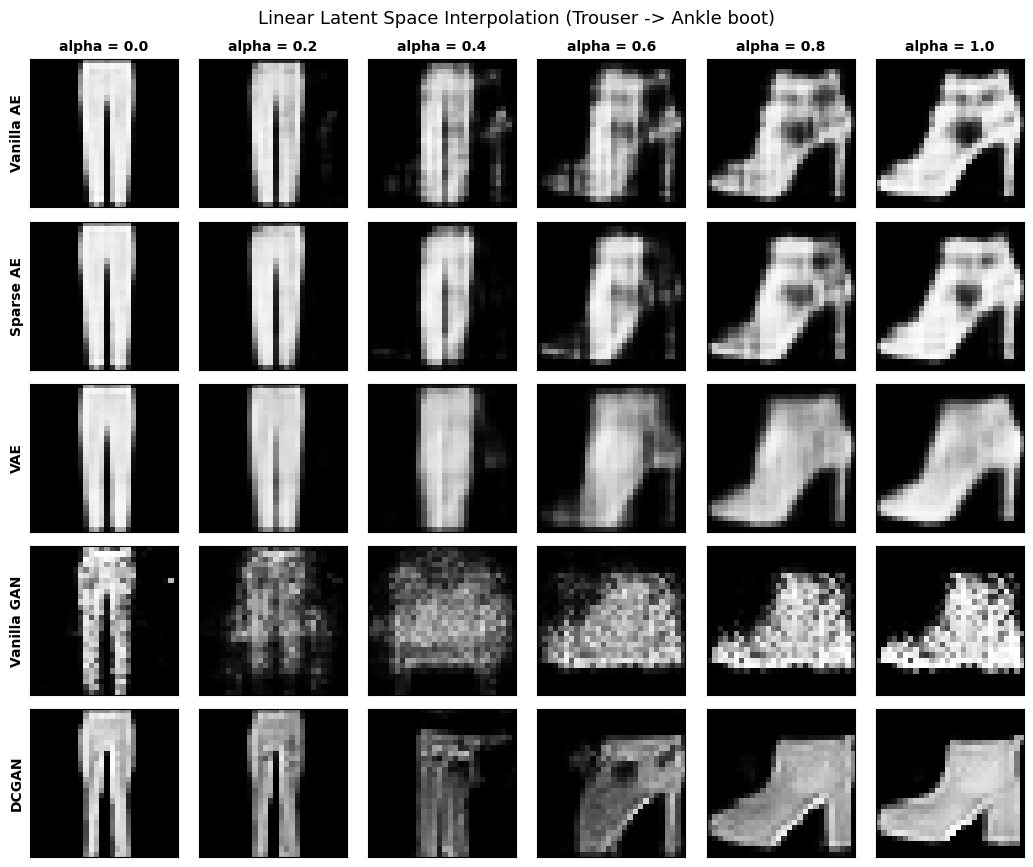

In [73]:
# Linear Latent Space Interpolation

alphas = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

cls_a = classes.index("Trouser")
cls_b = classes.index("Ankle boot")

idx_a = sample_labels.index(cls_a)
idx_b = sample_labels.index(cls_b)

x_a = x_real[idx_a:idx_a + 1]
x_b = x_real[idx_b:idx_b + 1]

def pick_gan_pair(gen_model):
    gen_model.eval()
    set_seed(seed)

    with torch.no_grad():
        z_pool = torch.randn(512, z_dim, device=device)
        imgs = (gen_model(z_pool) + 1) / 2
        imgs_flat = imgs.view(512, -1).clamp(0, 1)
        probs = F.softmax(mlp_head(mlp_enc(imgs_flat)), dim=1)
        best_a = probs[:, cls_a].argmax().item()
        best_b = probs[:, cls_b].argmax().item()
    return z_pool[best_a:best_a + 1], z_pool[best_b:best_b + 1], probs[best_a, cls_a].item(), probs[best_b, cls_b].item()

def interp_decode(z_a, z_b, dec_fn):
    out = []

    with torch.no_grad():
        for a in alphas:
            z = (1.0 - a) * z_a + a * z_b
            out.append(dec_fn(z).view(28, 28).cpu())
    return out

ae_enc.eval()
ae_dec.eval()
sae_enc.eval()
sae_dec.eval()
vae_enc.eval()
vae_mu.eval()
vae_dec.eval()
mlp_enc.eval()
mlp_head.eval()

with torch.no_grad():
    ae_row = interp_decode(ae_enc(x_a), ae_enc(x_b), ae_dec)
    sae_row = interp_decode(sae_enc(x_a), sae_enc(x_b), sae_dec)
    vae_row = interp_decode(vae_mu(vae_enc(x_a)), vae_mu(vae_enc(x_b)), vae_dec)

z_gan_a, z_gan_b, p_gan_a, p_gan_b = pick_gan_pair(gan_G)
gan_row = interp_decode(z_gan_a, z_gan_b, lambda z: ((gan_G(z) + 1) / 2).clamp(0, 1))

z_dc_a, z_dc_b, p_dc_a, p_dc_b = pick_gan_pair(dcgan_G)
dcgan_row = interp_decode(z_dc_a, z_dc_b, lambda z: ((dcgan_G(z) + 1) / 2).clamp(0, 1))

print(f"Kelas A: {classes[cls_a]}")
print(f"Kelas B: {classes[cls_b]}")
print(f"Confidence Vanilla GAN >> {classes[cls_a]}: {p_gan_a*100:.1f}%")
print(f"Confidence Vanilla GAN >> {classes[cls_b]}: {p_gan_b*100:.1f}%")
print(f"Confidence DCGAN >> {classes[cls_a]}: {p_dc_a*100:.1f}%")
print(f"Confidence DCGAN >> {classes[cls_b]}: {p_dc_b*100:.1f}%")

interp_rows = [ae_row, sae_row, vae_row, gan_row, dcgan_row]
interp_names = ["Vanilla AE", "Sparse AE", "VAE", "Vanilla GAN", "DCGAN"]

fig, axes = plt.subplots(5, len(alphas), figsize=(10.5, 8.8))
for r in range(5):
    for c, a in enumerate(alphas):
        axes[r, c].imshow(interp_rows[r][c], cmap="gray", vmin=0, vmax=1)
        if r == 0:
            axes[r, c].set_title(f"alpha = {a:.1f}", fontsize=10, fontweight="bold")
        axes[r, c].set_xticks([])
        axes[r, c].set_yticks([])
    axes[r, 0].set_ylabel(interp_names[r], fontsize=10, fontweight="bold")

plt.suptitle(f"Linear Latent Space Interpolation ({classes[cls_a]} -> {classes[cls_b]})", fontsize=13)
plt.tight_layout()
plt.savefig("outputs/figs/latent_interp.png", dpi=300, bbox_inches="tight")
plt.show()

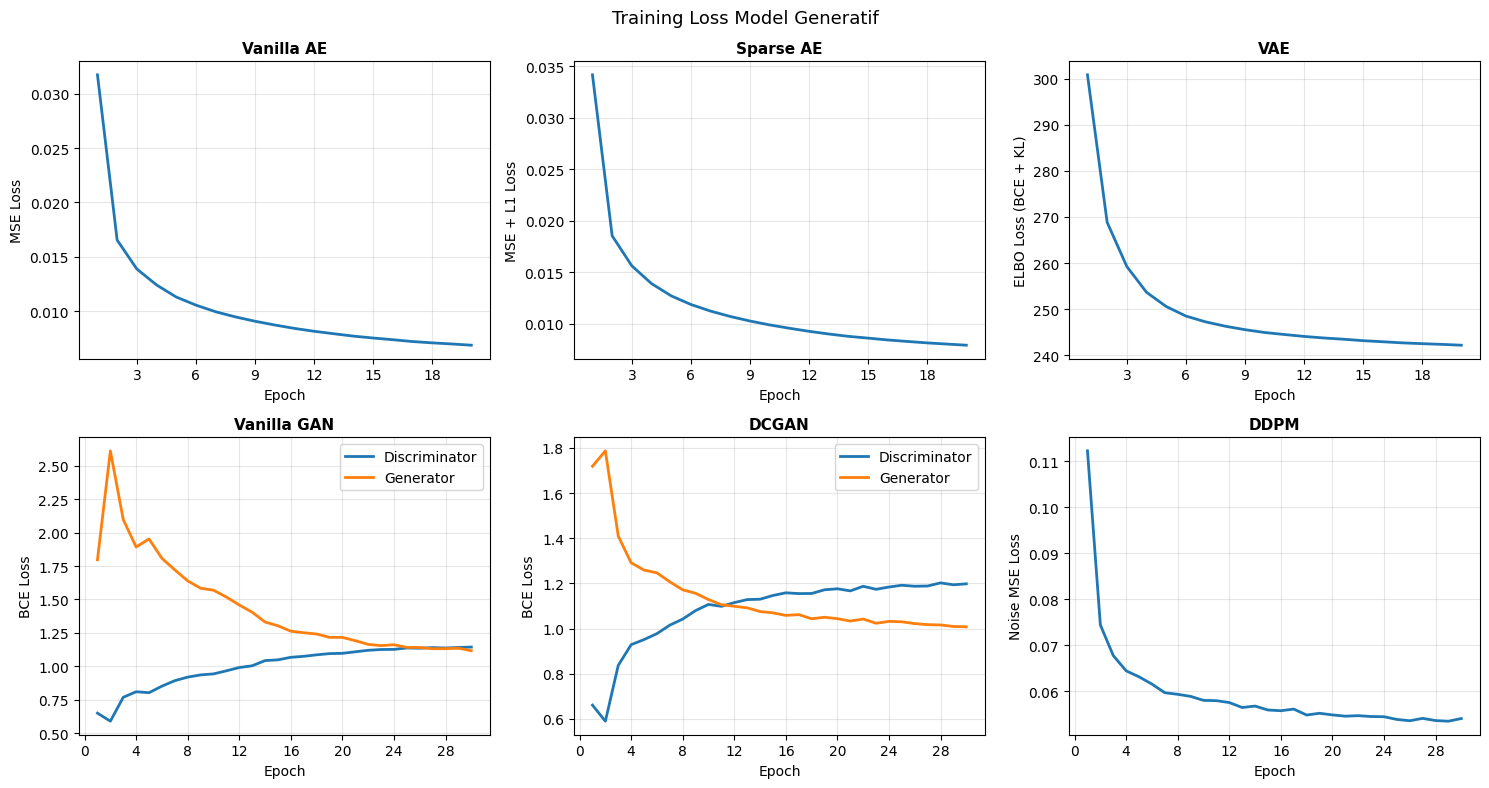

In [74]:
# Training Loss Curves

def load_loss(name):
    path = f"outputs/models/{name}_losses.npy"
    if not os.path.exists(path):
        raise FileNotFoundError(f"'{path}' tidak ditemukan")

    return np.load(path)

hist_ae = load_loss("ae")
hist_sae = load_loss("sae")
hist_vae = load_loss("vae")
hist_gan_g = load_loss("gan_g")
hist_gan_d = load_loss("gan_d")
hist_dcgan_g = load_loss("dcgan_g")
hist_dcgan_d = load_loss("dcgan_d")
hist_ddpm = load_loss("ddpm")

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# Autoencoder
single_plots = [
    (axes[0, 0], hist_ae, "Vanilla AE", "MSE Loss"),
    (axes[0, 1], hist_sae, "Sparse AE", "MSE + L1 Loss"),
    (axes[0, 2], hist_vae, "VAE", "ELBO Loss (BCE + KL)"),
]

for ax, data, title, ylabel in single_plots:
    ep = range(1, len(data) + 1)
    ax.plot(ep, data, linewidth=2)
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(True, alpha=0.3)

# GAN, DCGAN, dan DDPM
gan_plots = [
    (axes[1, 0], hist_gan_d, hist_gan_g, "Vanilla GAN"),
    (axes[1, 1], hist_dcgan_d, hist_dcgan_g, "DCGAN"),
]

for ax, d_data, g_data, title in gan_plots:
    ep = range(1, len(d_data) + 1)
    ax.plot(ep, d_data, label="Discriminator", linewidth=2)
    ax.plot(ep, g_data, label="Generator", linewidth=2)
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("BCE Loss")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.legend()
    ax.grid(True, alpha=0.3)

ep_ddpm = range(1, len(hist_ddpm) + 1)
axes[1, 2].plot(ep_ddpm, hist_ddpm, linewidth=2)
axes[1, 2].set_title("DDPM", fontsize=11, fontweight="bold")
axes[1, 2].set_xlabel("Epoch")
axes[1, 2].set_ylabel("Noise MSE Loss")
axes[1, 2].xaxis.set_major_locator(MaxNLocator(integer=True))
axes[1, 2].grid(True, alpha=0.3)

plt.suptitle("Training Loss Model Generatif", fontsize=13)
plt.tight_layout()
plt.savefig("outputs/figs/kurva_loss.png", dpi=300, bbox_inches="tight")
plt.show()

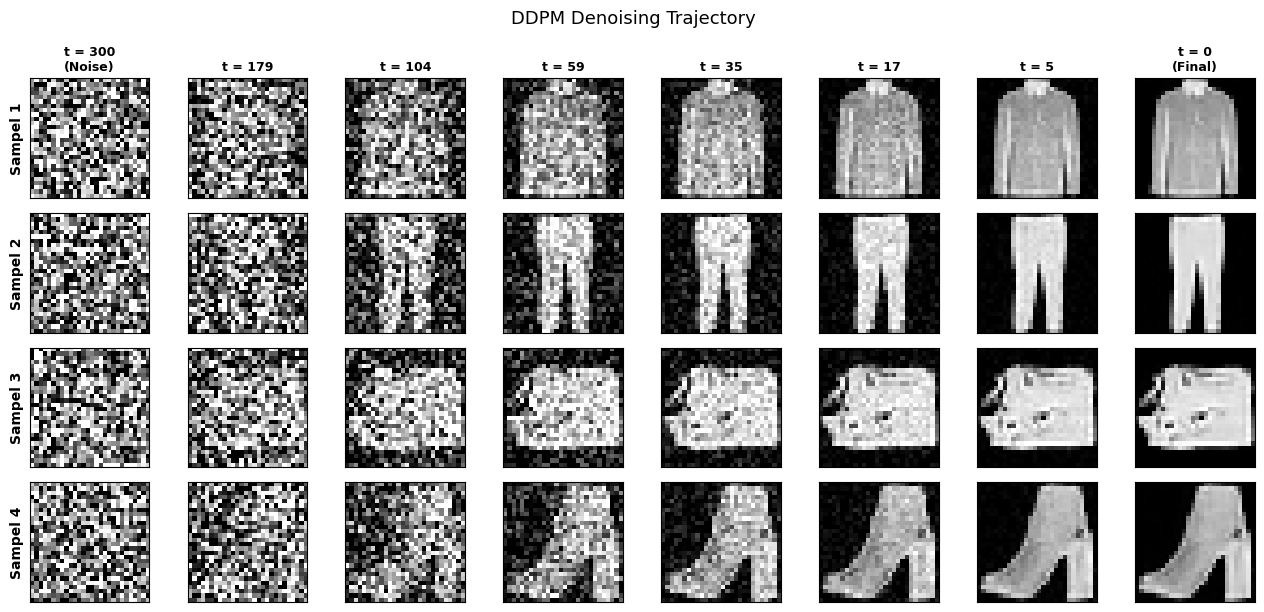

In [75]:
# DDPM Denoising Trajectory

set_seed(seed)
n_traj = 4
x = torch.randn(n_traj, 1, 28, 28, device=device)

ratio = [0.60, 0.35, 0.20, 0.12, 0.06, 0.02, 0.0]
snap_steps = sorted({int(r * (T - 1)) for r in ratio}, reverse=True)

traj_imgs = [((x.clamp(-1, 1) + 1) / 2).squeeze(1).cpu()]
traj_labels = [f"t = {T}\n(Noise)"]

ddpm_net.eval()

with torch.no_grad():
    for i in reversed(range(T)):
        t = torch.full((n_traj,), i, device=device, dtype=torch.long)
        pred = ddpm_net(x, t)
        a = alpha[i]
        ab = alpha_bar[i]
        b = betas[i]

        x = (1 / torch.sqrt(a)) * (x - ((1 - a) / torch.sqrt(1 - ab)) * pred)
        if i > 0:
            var = b * (1 - alpha_bar[i - 1]) / (1 - ab)
            x = x + torch.sqrt(var) * torch.randn_like(x)

        if i in snap_steps:
            traj_imgs.append(((x.clamp(-1, 1) + 1) / 2).squeeze(1).cpu())
            label = "t = 0\n(Final)" if i == 0 else f"t = {i}"
            traj_labels.append(label)

n_cols = len(traj_imgs)
fig, axes = plt.subplots(n_traj, n_cols, figsize=(13, 6.2))

for r in range(n_traj):
    for c in range(n_cols):
        axes[r, c].imshow(traj_imgs[c][r], cmap="gray", vmin=0, vmax=1)
        if r == 0:
            axes[r, c].set_title(traj_labels[c], fontsize=9, fontweight="bold")
        axes[r, c].set_xticks([])
        axes[r, c].set_yticks([])
    axes[r, 0].set_ylabel(f"Sampel {r+1}", fontsize=10, fontweight="bold")

plt.suptitle("DDPM Denoising Trajectory", fontsize=13)
plt.tight_layout()
plt.savefig("outputs/figs/ddpm_trajectory.png", dpi=300, bbox_inches="tight")
plt.show()

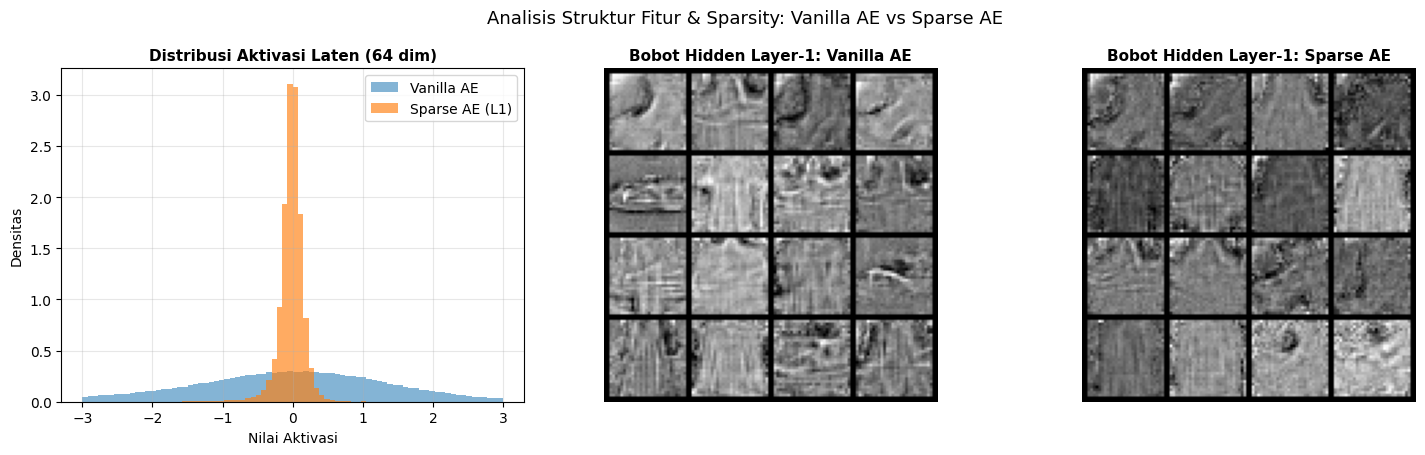

In [78]:
# Struktur Fitur Hidden Layer Sparse AE vs Vanilla AE

ae_enc.eval()
sae_enc.eval()

z_ae_all, h_sae_all = [], []
with torch.no_grad():
    for imgs, _ in test_loader:
        x_flat = imgs.view(imgs.size(0), -1).to(device)
        z_ae_all.append(ae_enc(x_flat).cpu())
        h_sae_all.append(sae_enc(x_flat).cpu())

z_ae_np = torch.cat(z_ae_all, dim=0).numpy().ravel()
h_sae_np = torch.cat(h_sae_all, dim=0).numpy().ravel()

w_ae = ae_enc[0].weight.detach().cpu()
w_sae = sae_enc[0].weight.detach().cpu()
top_ae = w_ae[w_ae.norm(dim=1).topk(16).indices].view(16, 1, 28, 28)
top_sae = w_sae[w_sae.norm(dim=1).topk(16).indices].view(16, 1, 28, 28)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))

axes[0].hist(z_ae_np, bins=80, range=(-3, 3), density=True, alpha=0.55, label="Vanilla AE")
axes[0].hist(h_sae_np, bins=80, range=(-3, 3), density=True, alpha=0.65, label="Sparse AE (L1)")
axes[0].set_title("Distribusi Aktivasi Laten (64 dim)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Nilai Aktivasi")
axes[0].set_ylabel("Densitas")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

grid_ae = make_grid(top_ae, nrow=4, padding=2, normalize=True, scale_each=True)
axes[1].imshow(grid_ae[0], cmap="gray")
axes[1].set_title("Bobot Hidden Layer-1: Vanilla AE", fontsize=11, fontweight="bold")
axes[1].axis("off")

grid_sae = make_grid(top_sae, nrow=4, padding=2, normalize=True, scale_each=True)
axes[2].imshow(grid_sae[0], cmap="gray")
axes[2].set_title("Bobot Hidden Layer-1: Sparse AE", fontsize=11, fontweight="bold")
axes[2].axis("off")

plt.suptitle("Analisis Struktur Fitur & Sparsity: Vanilla AE vs Sparse AE", fontsize=13)
plt.tight_layout()
plt.savefig("outputs/figs/sae_feature_analysis.png", dpi=300, bbox_inches="tight")
plt.show()

=== Cek Mode Collapse ===
VAE          | Norm Entropy: 0.9741 | Min:  5.5% (Ankle boot) | Max: 16.9% (Coat)
Vanilla GAN  | Norm Entropy: 0.9730 | Min:  4.7% (Pullover) | Max: 15.7% (Coat)
DCGAN        | Norm Entropy: 0.9915 | Min:  7.6% (Pullover) | Max: 14.4% (Coat)
DDPM         | Norm Entropy: 0.9728 | Min:  5.6% (Sneaker) | Max: 18.2% (Coat)


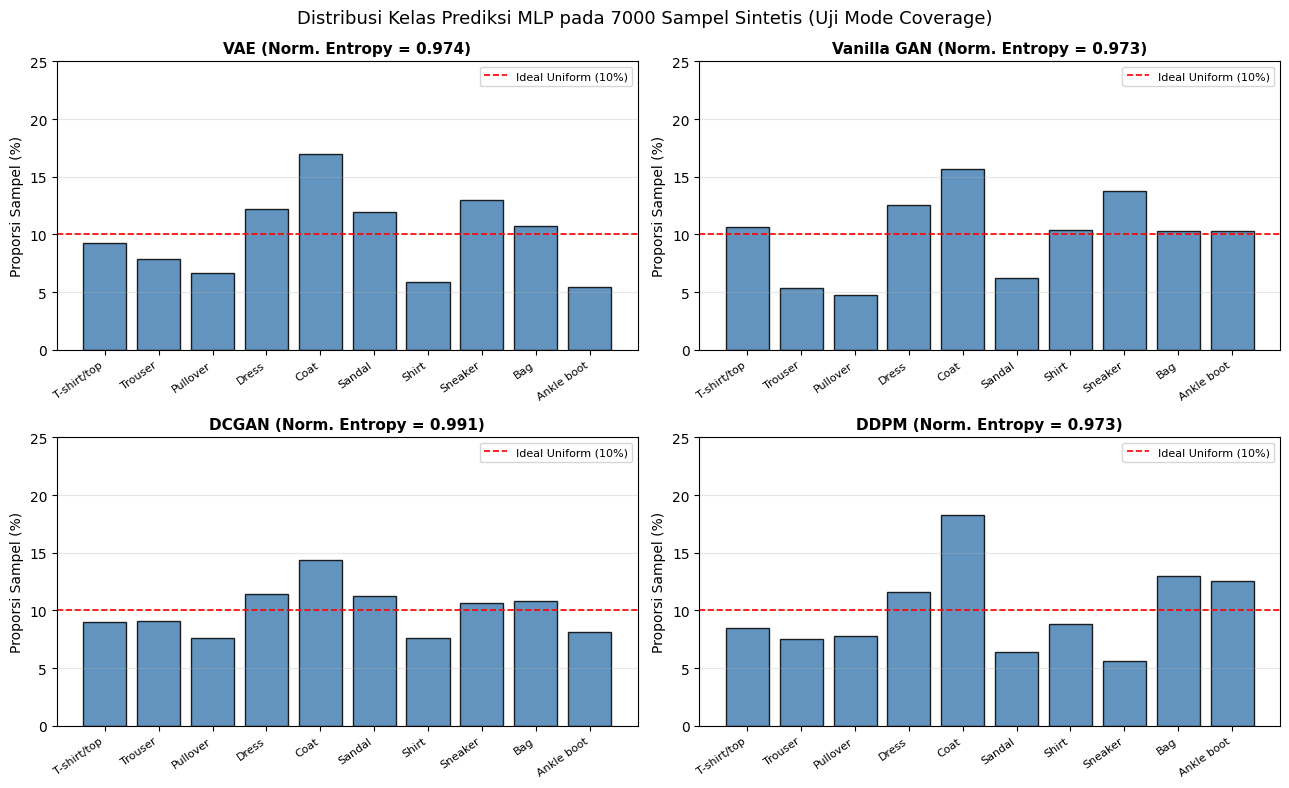

In [80]:
# Cek Mode Collapse

mlp_enc.eval()
mlp_head.eval()
vae_dec.eval()
gan_G.eval()
dcgan_G.eval()
ddpm_net.eval()

n_eval = len(test_data)

def eval_mode_coverage(gen_fn, batch_sz=128):
    set_seed(seed)
    counts = np.zeros(len(classes), dtype=int)
    done = 0
    with torch.no_grad():
        while done < n_eval:
            bs = min(batch_sz, n_eval - done)
            imgs_flat = gen_fn(bs).view(bs, -1).clamp(0, 1)
            preds = mlp_head(mlp_enc(imgs_flat)).argmax(dim=1).cpu().numpy()
            counts += np.bincount(preds, minlength=len(classes))
            done += bs
    probs = counts / counts.sum()
    norm_entropy = -np.sum(probs * np.log(probs + 1e-12)) / np.log(len(classes))
    return probs * 100, norm_entropy

cov_models = [
    ("VAE", lambda bs: vae_dec(torch.randn(bs, 64, device=device)), 128),
    ("Vanilla GAN", lambda bs: (gan_G(torch.randn(bs, z_dim, device=device)) + 1) / 2, 128),
    ("DCGAN", lambda bs: (dcgan_G(torch.randn(bs, z_dim, device=device)) + 1) / 2, 128),
    ("DDPM", lambda bs: sample_ddpm(bs), 256),
]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
print(f"=== Cek Mode Collapse ===")

for idx, (name, fn, bsz) in enumerate(cov_models):
    pct, ent = eval_mode_coverage(fn, bsz)
    min_i, max_i = np.argmin(pct), np.argmax(pct)
    print(f"{name:<12} | Norm Entropy: {ent:.4f} | "
          f"Min: {pct[min_i]:4.1f}% ({classes[min_i]}) | "
          f"Max: {pct[max_i]:4.1f}% ({classes[max_i]})")

    ax = axes[idx // 2, idx % 2]
    ax.bar(range(10), pct, color="steelblue", edgecolor="black", alpha=0.85)
    ax.axhline(10.0, color="red", linestyle="--", linewidth=1.2, label="Ideal Uniform (10%)")
    ax.set_title(f"{name} (Norm. Entropy = {ent:.3f})", fontsize=11, fontweight="bold")
    ax.set_xticks(range(10))
    ax.set_xticklabels(classes, rotation=35, ha="right", fontsize=8)
    ax.set_ylabel("Proporsi Sampel (%)")
    ax.set_ylim(0, max(25, pct.max() + 4))
    ax.legend(fontsize=8)
    ax.grid(True, axis="y", alpha=0.3)

plt.suptitle(f"Distribusi Kelas Prediksi MLP pada {n_eval} Sampel Sintetis (Uji Mode Coverage)", fontsize=13)
plt.tight_layout()
plt.savefig("outputs/figs/mode_coverage.png", dpi=300, bbox_inches="tight")
plt.show()

=== Anomaly Detection (Train: 9 Kelas Normal = 50400 citra | Anomali: Sandal) ===
Vanilla AE   | Normal MSE: 0.00667 | Anomali (Sandal) MSE: 0.01684 | AUROC: 0.8864
Sparse AE    | Normal MSE: 0.00693 | Anomali (Sandal) MSE: 0.01690 | AUROC: 0.8786


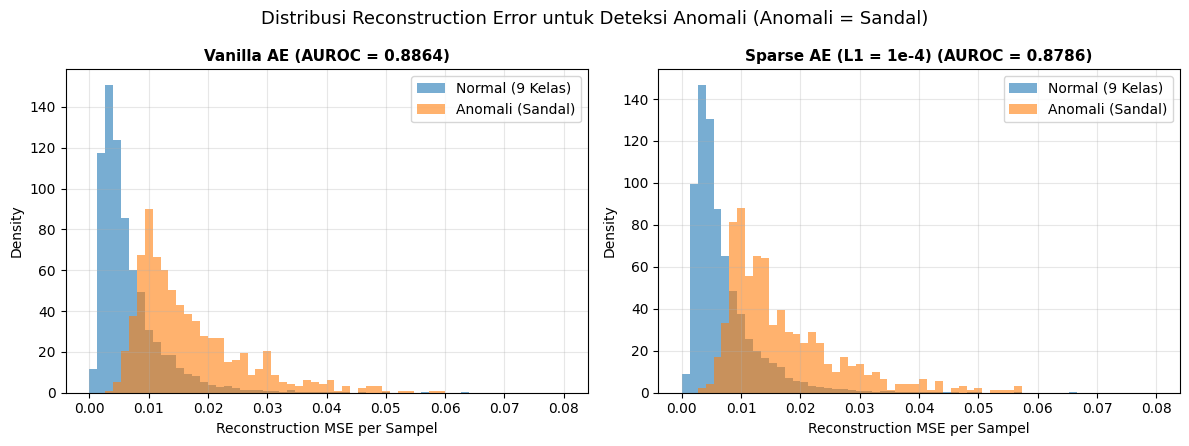

In [81]:
# Eksperimen Anomaly Detection

from sklearn.metrics import roc_auc_score

anom_cls = classes.index("Sandal")
normal_train_idx = train_idx[all_labels[train_idx] != anom_cls]
normal_train_loader = DataLoader(Subset(full_data, normal_train_idx), batch_size=batch_size, shuffle=True)

def run_anomaly_exp(lam_val, label_name):
    set_seed(seed)
    enc = nn.Sequential(nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, 64)).to(device)
    dec = nn.Sequential(nn.Linear(64, 256), nn.ReLU(), nn.Linear(256, 784), nn.Sigmoid()).to(device)
    opt = optim.Adam(list(enc.parameters()) + list(dec.parameters()), lr=1e-3)

    for epoch in range(20):
        enc.train()
        dec.train()

        for imgs, _ in normal_train_loader:
            x = imgs.view(imgs.size(0), -1).to(device)
            opt.zero_grad()
            h = enc(x)
            loss = mse_fn(dec(h), x)

            if lam_val > 0:
                loss = loss + lam_val * h.abs().sum(dim=1).mean()
            loss.backward()
            opt.step()

    enc.eval()
    dec.eval()
    scores, y_true = [], []

    with torch.no_grad():
        for imgs, labels in test_loader:
            x = imgs.view(imgs.size(0), -1).to(device)
            recon = dec(enc(x))
            err = F.mse_loss(recon, x, reduction="none").mean(dim=1).cpu().numpy()
            scores.append(err)
            y_true.append((labels == anom_cls).int().numpy())

    scores = np.concatenate(scores)
    y_true = np.concatenate(y_true)
    auroc = roc_auc_score(y_true, scores)
    norm_mse = scores[y_true == 0].mean()
    anom_mse = scores[y_true == 1].mean()
    print(f"{label_name:<12} | Normal MSE: {norm_mse:.5f} | Anomali ({classes[anom_cls]}) MSE: {anom_mse:.5f} | AUROC: {auroc:.4f}")

    return scores, y_true, auroc

print(f"=== Anomaly Detection (Train: 9 Kelas Normal = {len(normal_train_idx)} citra | Anomali: {classes[anom_cls]}) ===")
sc_ae, y_ae, auc_ae = run_anomaly_exp(0.0, "Vanilla AE")
sc_sae, y_sae, auc_sae = run_anomaly_exp(1e-4, "Sparse AE")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, sc, yt, auc, title in [
    (axes[0], sc_ae, y_ae, auc_ae, "Vanilla AE"),
    (axes[1], sc_sae, y_sae, auc_sae, "Sparse AE (L1 = 1e-4)"),
]:
    ax.hist(sc[yt == 0], bins=60, range=(0, 0.08), density=True, alpha=0.6, label="Normal (9 Kelas)")
    ax.hist(sc[yt == 1], bins=60, range=(0, 0.08), density=True, alpha=0.6, label=f"Anomali ({classes[anom_cls]})")
    ax.set_title(f"{title} (AUROC = {auc:.4f})", fontsize=11, fontweight="bold")
    ax.set_xlabel("Reconstruction MSE per Sampel")
    ax.set_ylabel("Density")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.suptitle(f"Distribusi Reconstruction Error untuk Deteksi Anomali (Anomali = {classes[anom_cls]})", fontsize=13)
plt.tight_layout()
plt.savefig("outputs/figs/anomaly_detection.png", dpi=300, bbox_inches="tight")
plt.show()

In [82]:
!mkdir -p "/content/drive/MyDrive/DL_Sesi07_Outputs"
!cp -r outputs/* "/content/drive/MyDrive/DL_Sesi07_Outputs/"